Data Collection and Cleaning

In [2]:
pip install yfinance

  Using cached cffi-2.0.0-cp313-cp313-macosx_11_0_arm64.whl.metadata (2.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 5.0 MB/s eta 0:00:00a 0:00:01
Using cached cffi-2.0.0-cp313-cp313-macosx_11_0_arm64.whl (181 kB)
  Attempting uninstall: cffi
    Found existing installation: cffi 1.17.1
    Uninstalling cffi-1.17.1:
      Successfully uninstalled cffi-1.17.1━━━━━━━━━━━━━━━━━━━ 3/6 [cffi]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [yfinance]5/6 [yfinance]
Note: you may need to restart the kernel to use updated packages.


In [7]:
# =========================================================================
# STEP 1: IMPORTING LIBRARIES & CONFIGURING PARAMETERS
# =========================================================================
import yfinance as yf
import pandas as pd
import numpy as np

# Define perfectly balanced sectors (3 Stocks per Sector + 1 Benchmark)
ticker_sectors = {
    'HDFCBANK.NS': 'BANK', 'ICICIBANK.NS': 'BANK', 'AXISBANK.NS': 'BANK',
    'TCS.NS': 'IT', 'INFY.NS': 'IT', 'WIPRO.NS': 'IT',
    'RELIANCE.NS': 'ENERGY', 'ONGC.NS': 'ENERGY', 'BPCL.NS': 'ENERGY',
    'MARUTI.NS': 'AUTO', 'HEROMOTOCO.NS': 'AUTO', 'M&M.NS': 'AUTO'
}
tickers = list(ticker_sectors.keys())
benchmark = '^NSEI'  # NIFTY 50 Benchmark

# Hardcoded 5-year historical date range
start_date = "2021-04-01"
end_date = "2026-03-31"  

# =========================================================================
# STEP 2: RAW DATA DOWNLOAD via yfinance
# =========================================================================
print("--- Initializing Data Download via yfinance ---")
raw_data = yf.download(tickers + [benchmark], start=start_date, end=end_date, auto_adjust=False)

# =========================================================================
# STEP 3: PRE-CLEANING AUDIT - MISSING VALUES PER TICKER
# =========================================================================
print("\n" + "="*70)
print("   SUBMISSION OUTPUT: PRE-CLEANING MISSING VALUE AUDIT PER TICKER")
print("="*70)
for ticker in tickers:
    df_ticker_raw = raw_data.xs(ticker, level='Ticker', axis=1)
    missing_close = df_ticker_raw['Adj Close'].isnull().sum()
    missing_volume = df_ticker_raw['Volume'].isnull().sum()
    print(f"Ticker: {ticker:<15} | Raw Missing Adj Close: {missing_close:<3} | Raw Missing Volume: {missing_volume}")

# Check raw benchmark index missing data
bench_raw_check = raw_data.xs(benchmark, level='Ticker', axis=1)
bench_missing = bench_raw_check['Adj Close'].isnull().sum()
print(f"Benchmark: {benchmark:<12} | Raw Missing Adj Close: {bench_missing:<3} | (Index - No Volume Check)")
print("="*70)

# =========================================================================
# STEP 4: DATA CLEANING & RE-ENGINEERING PIPELINE
# =========================================================================
quality_log = []
cleaned_stocks = {}

# Process Benchmark (Explicit .copy() protects against SettingWithCopyWarning)
bench_raw = raw_data.xs(benchmark, level='Ticker', axis=1).copy()
bench_nulls = bench_raw['Adj Close'].isnull().sum()
bench_raw['Adj Close'] = bench_raw['Adj Close'].ffill()  # Forward fill closing prices
benchmark_df = bench_raw[['Adj Close']].rename(columns={'Adj Close': 'Benchmark'})

quality_log.append({
    'Ticker': benchmark, 
    'Sector': 'BENCHMARK', 
    'Missing Values Found': bench_nulls, 
    'Action Taken': 'ffill'
})

# Process all 12 individual stocks
for ticker in tickers:
    df_ticker = raw_data.xs(ticker, level='Ticker', axis=1).copy()
    
    # Audit native null records prior to ingestion
    null_counts = df_ticker['Adj Close'].isnull().sum()
    vol_nulls = df_ticker['Volume'].isnull().sum()
    
    # Execute cleaning algorithms
    df_ticker['Adj Close'] = df_ticker['Adj Close'].ffill()   # Forward fill missing market close prices
    df_ticker['Volume'] = df_ticker['Volume'].fillna(0)       # Set missing volume blocks to 0
    df_ticker = df_ticker.drop_duplicates()                   # Erase duplicate timestamp entries
    
    cleaned_stocks[ticker] = df_ticker
    quality_log.append({
        'Ticker': ticker, 
        'Sector': ticker_sectors[ticker], 
        'Missing Values Found': null_counts, 
        'Action Taken': f'ffill Adj Close, fillna(0) Vol={vol_nulls}, drop_duplicates'
    })

# =========================================================================
# STEP 5: COMMON TIMELINE ALIGNMENT VIA MULTI-LATERAL INNER JOIN
# =========================================================================
aligned_df = benchmark_df.copy()
for ticker, df in cleaned_stocks.items():
    # Structural join forces an intersection on valid matching trading dates
    aligned_df = aligned_df.join(df[['Adj Close', 'Volume', 'Close']].add_prefix(f'{ticker}_'), how='inner')

# Explicitly confirm and enforce standard DatetimeIndex format
aligned_df.index = pd.to_datetime(aligned_df.index)

# =========================================================================
# STEP 6: MANDATED CELL DELIVERABLE OUTPUTS (SHAPE, DATE RANGES, LOG TABLE)
# =========================================================================
print("\n" + "="*70)
print("                  DELIVERABLE: DATA QUALITY LOG TABLE")
print("="*70)
log_df = pd.DataFrame(quality_log)
print(log_df.to_string(index=False))
print("="*70)

print(f"\nFinal Aligned Dataset Shape: {aligned_df.shape} (Trading Days x Columns)")
print(f"Total Portfolio Boundaries: {len(tickers)} Stocks × {len(aligned_df)} Mutual Trading Days\n")

print("="*70)
print("                 SUBMISSION OUTPUT: TICKER DATE RANGES")
print("="*70)
print(f"Master Aligned Timeline: From {aligned_df.index.min().strftime('%Y-%m-%d')} to {aligned_df.index.max().strftime('%Y-%m-%d')}")
print("-" * 70)

# Loop to report boundaries and structural shape metrics for each asset
for ticker in tickers:
    ticker_raw = raw_data.xs(ticker, level='Ticker', axis=1)
    valid_dates = ticker_raw.dropna(how='all').index
    
    start_dt = valid_dates.min().strftime('%Y-%m-%d')
    end_dt = valid_dates.max().strftime('%Y-%m-%d')
    
    print(f"Ticker: {ticker:<15} | Active Date Range: {start_dt} to {end_dt} | Shape: {ticker_raw.shape}")
print("="*70)

[*********************100%***********************]  13 of 13 completed

--- Initializing Data Download via yfinance ---

   SUBMISSION OUTPUT: PRE-CLEANING MISSING VALUE AUDIT PER TICKER
Ticker: HDFCBANK.NS     | Raw Missing Adj Close: 0   | Raw Missing Volume: 0
Ticker: ICICIBANK.NS    | Raw Missing Adj Close: 0   | Raw Missing Volume: 0
Ticker: AXISBANK.NS     | Raw Missing Adj Close: 0   | Raw Missing Volume: 0
Ticker: TCS.NS          | Raw Missing Adj Close: 0   | Raw Missing Volume: 0
Ticker: INFY.NS         | Raw Missing Adj Close: 0   | Raw Missing Volume: 0
Ticker: WIPRO.NS        | Raw Missing Adj Close: 0   | Raw Missing Volume: 0
Ticker: RELIANCE.NS     | Raw Missing Adj Close: 0   | Raw Missing Volume: 0
Ticker: ONGC.NS         | Raw Missing Adj Close: 0   | Raw Missing Volume: 0
Ticker: BPCL.NS         | Raw Missing Adj Close: 0   | Raw Missing Volume: 0
Ticker: MARUTI.NS       | Raw Missing Adj Close: 0   | Raw Missing Volume: 0
Ticker: HEROMOTOCO.NS   | Raw Missing Adj Close: 0   | Raw Missing Volume: 0
Ticker: M&M.NS          | Raw Missing 

Metric Calculation & Dashboard Generation

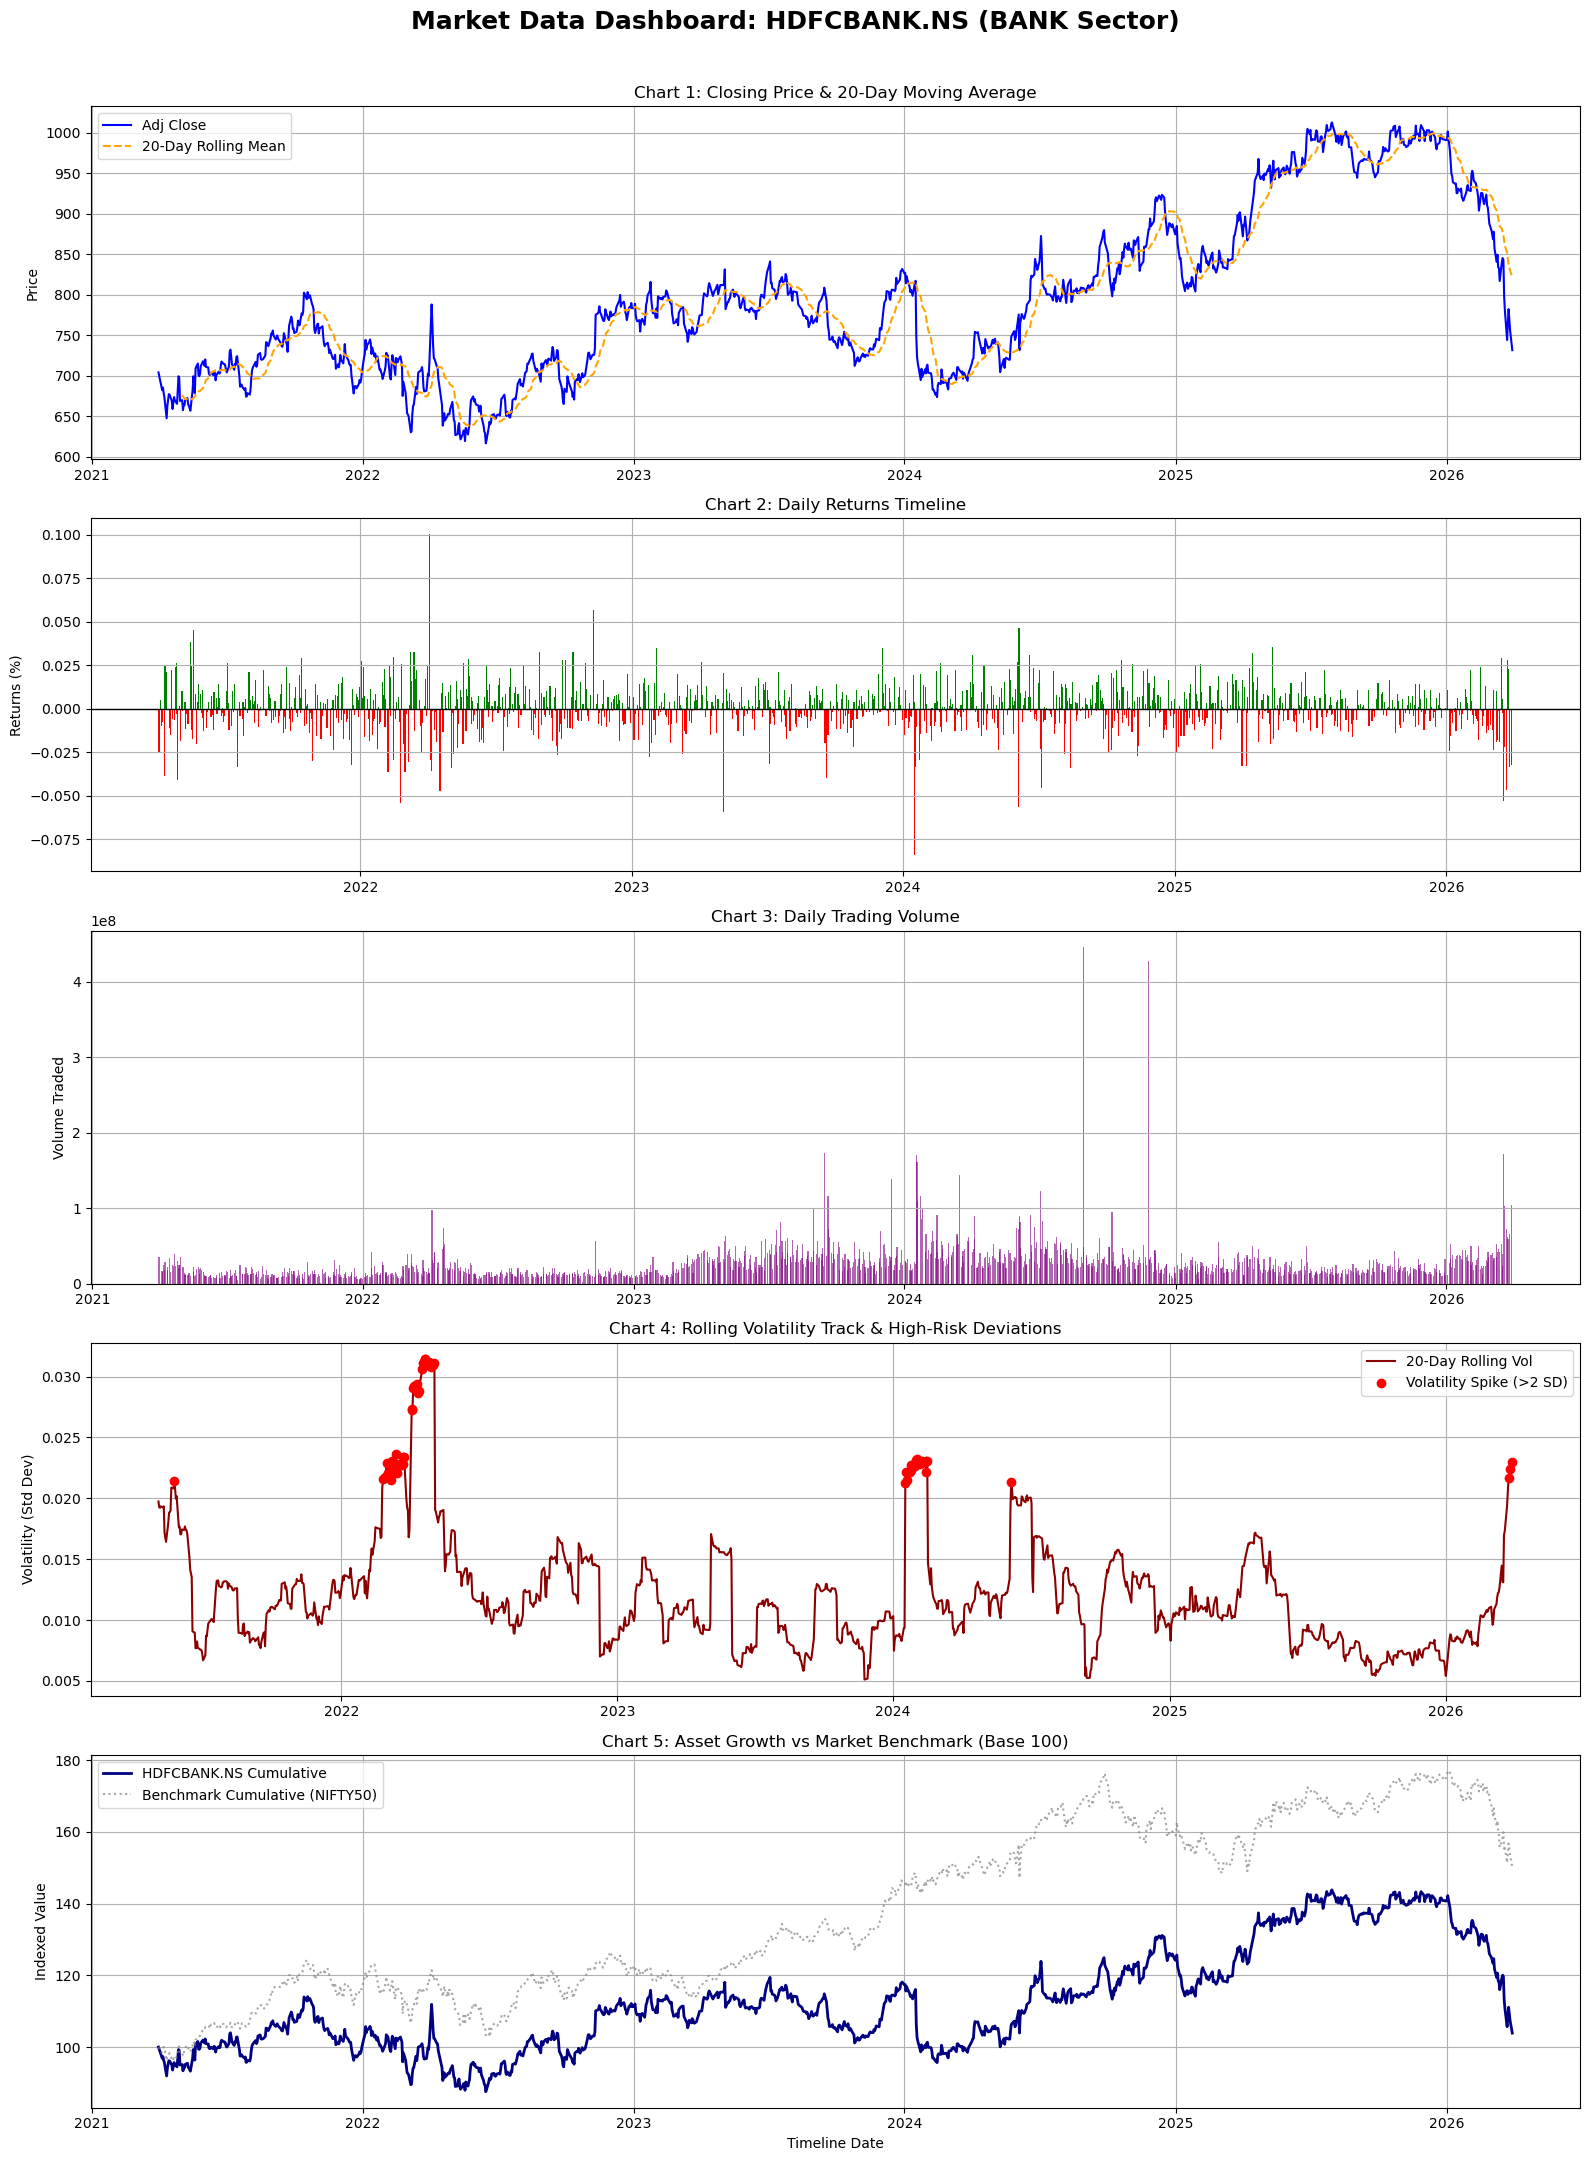

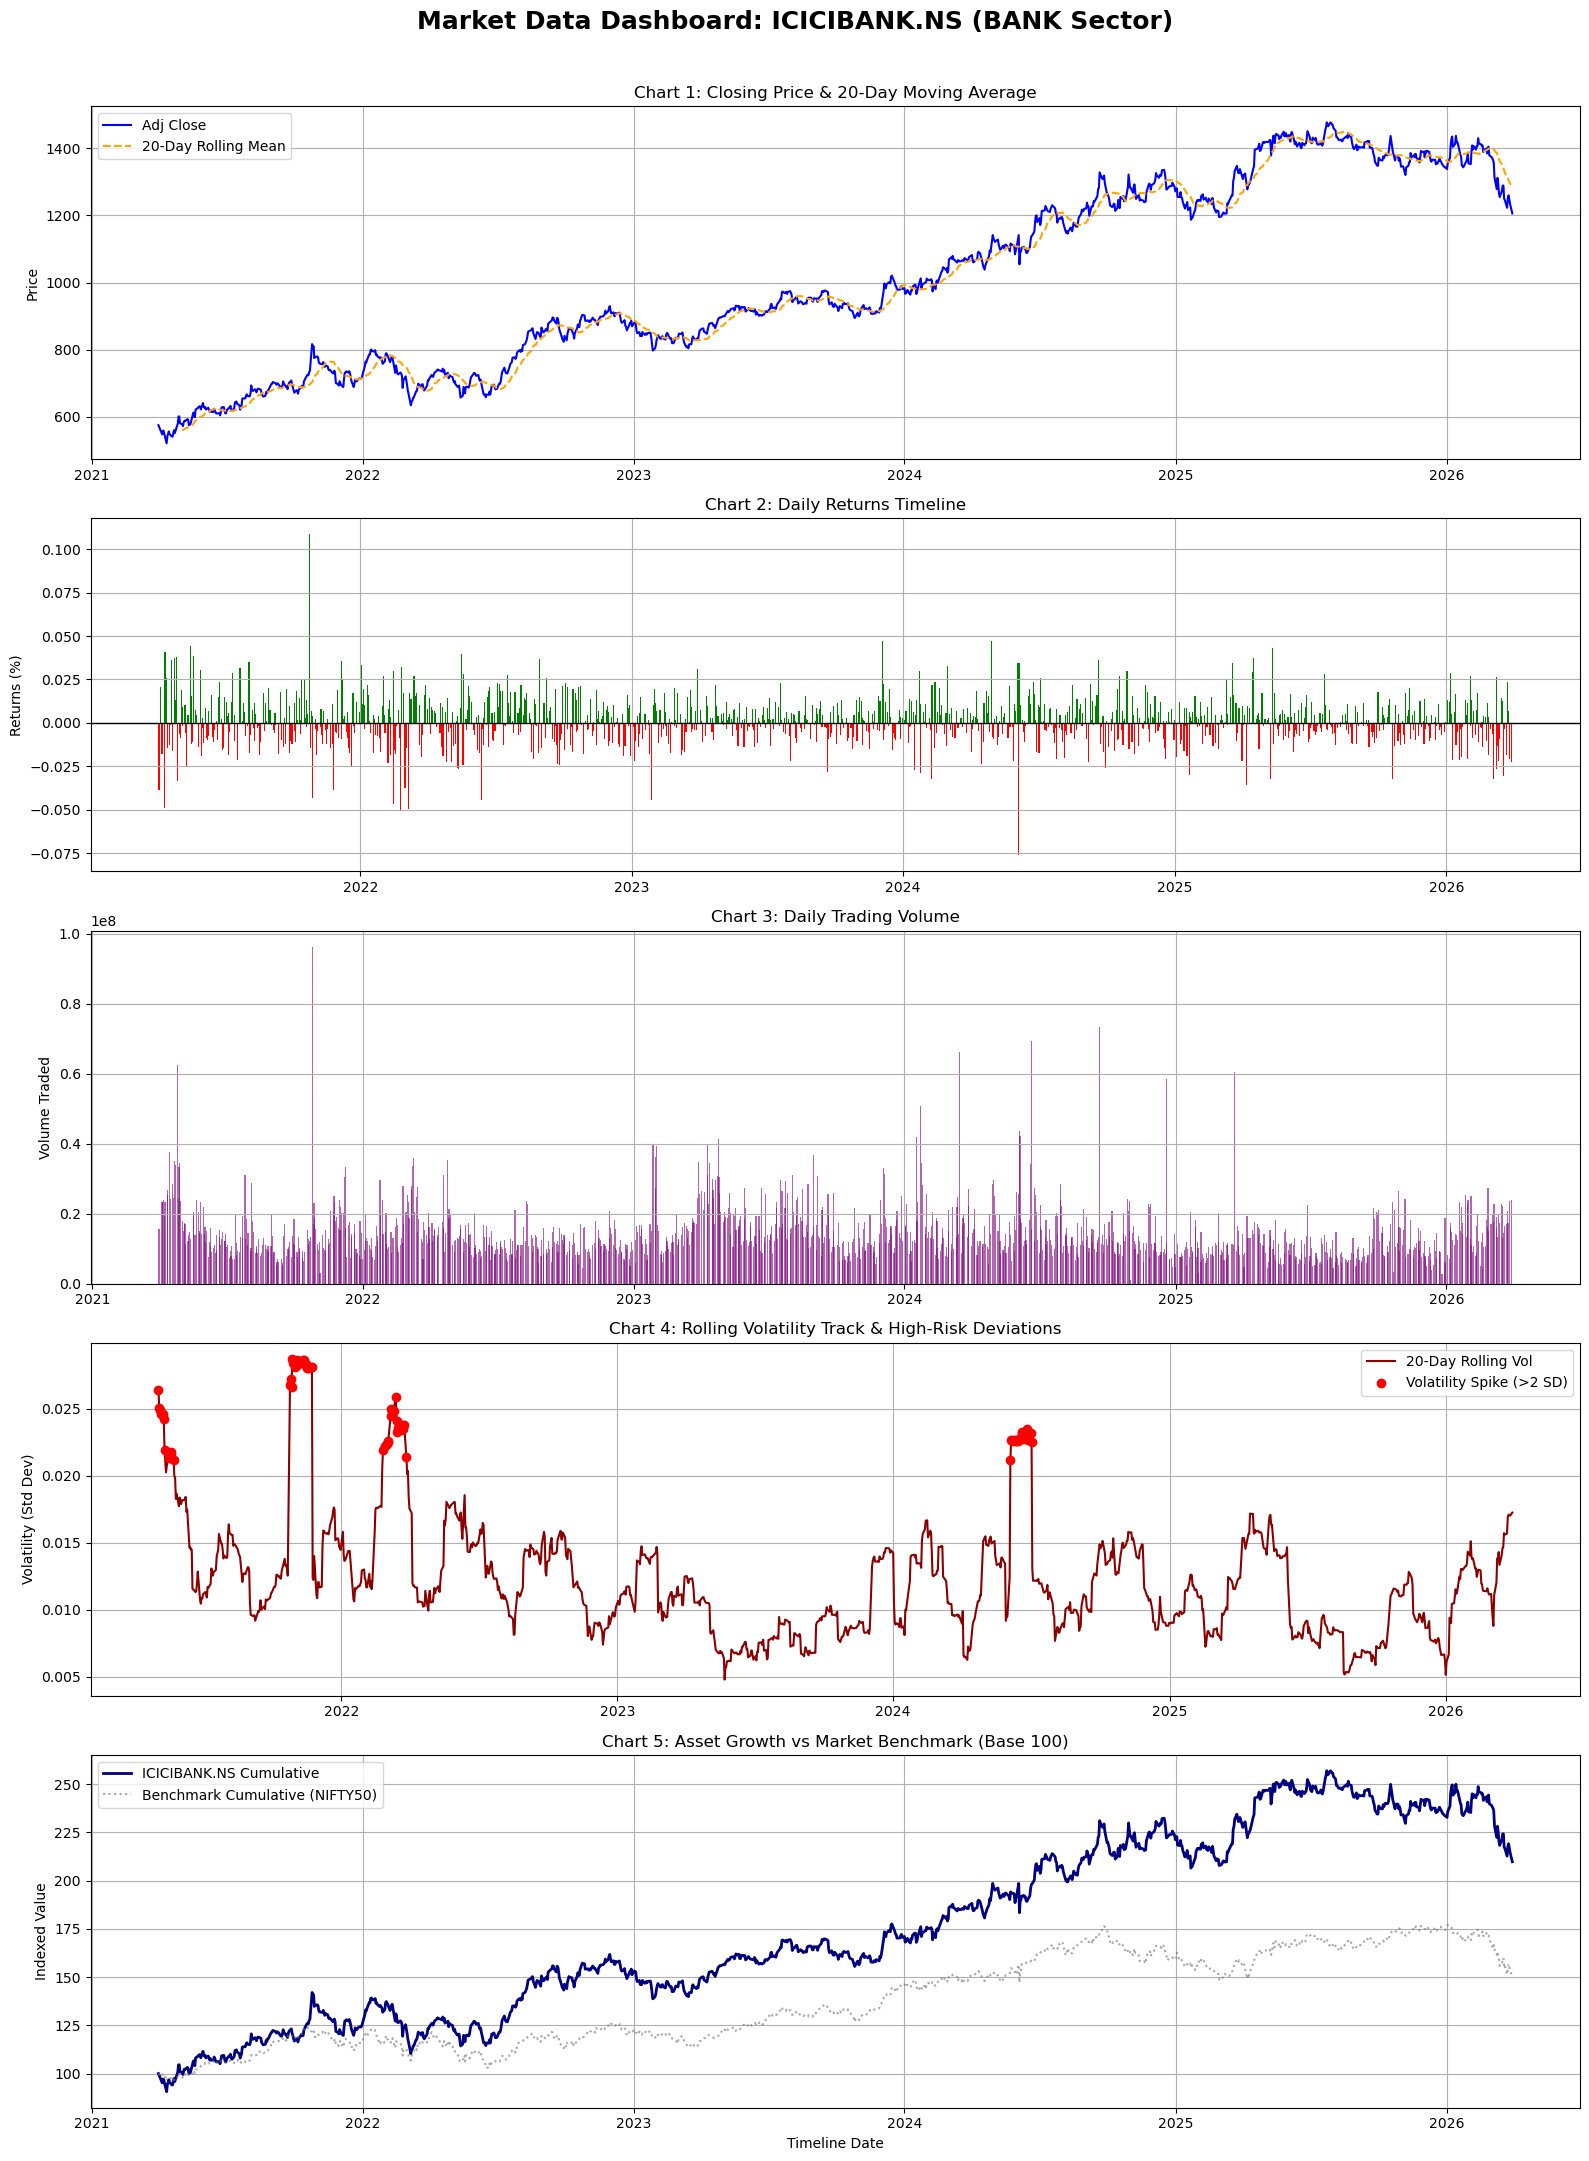

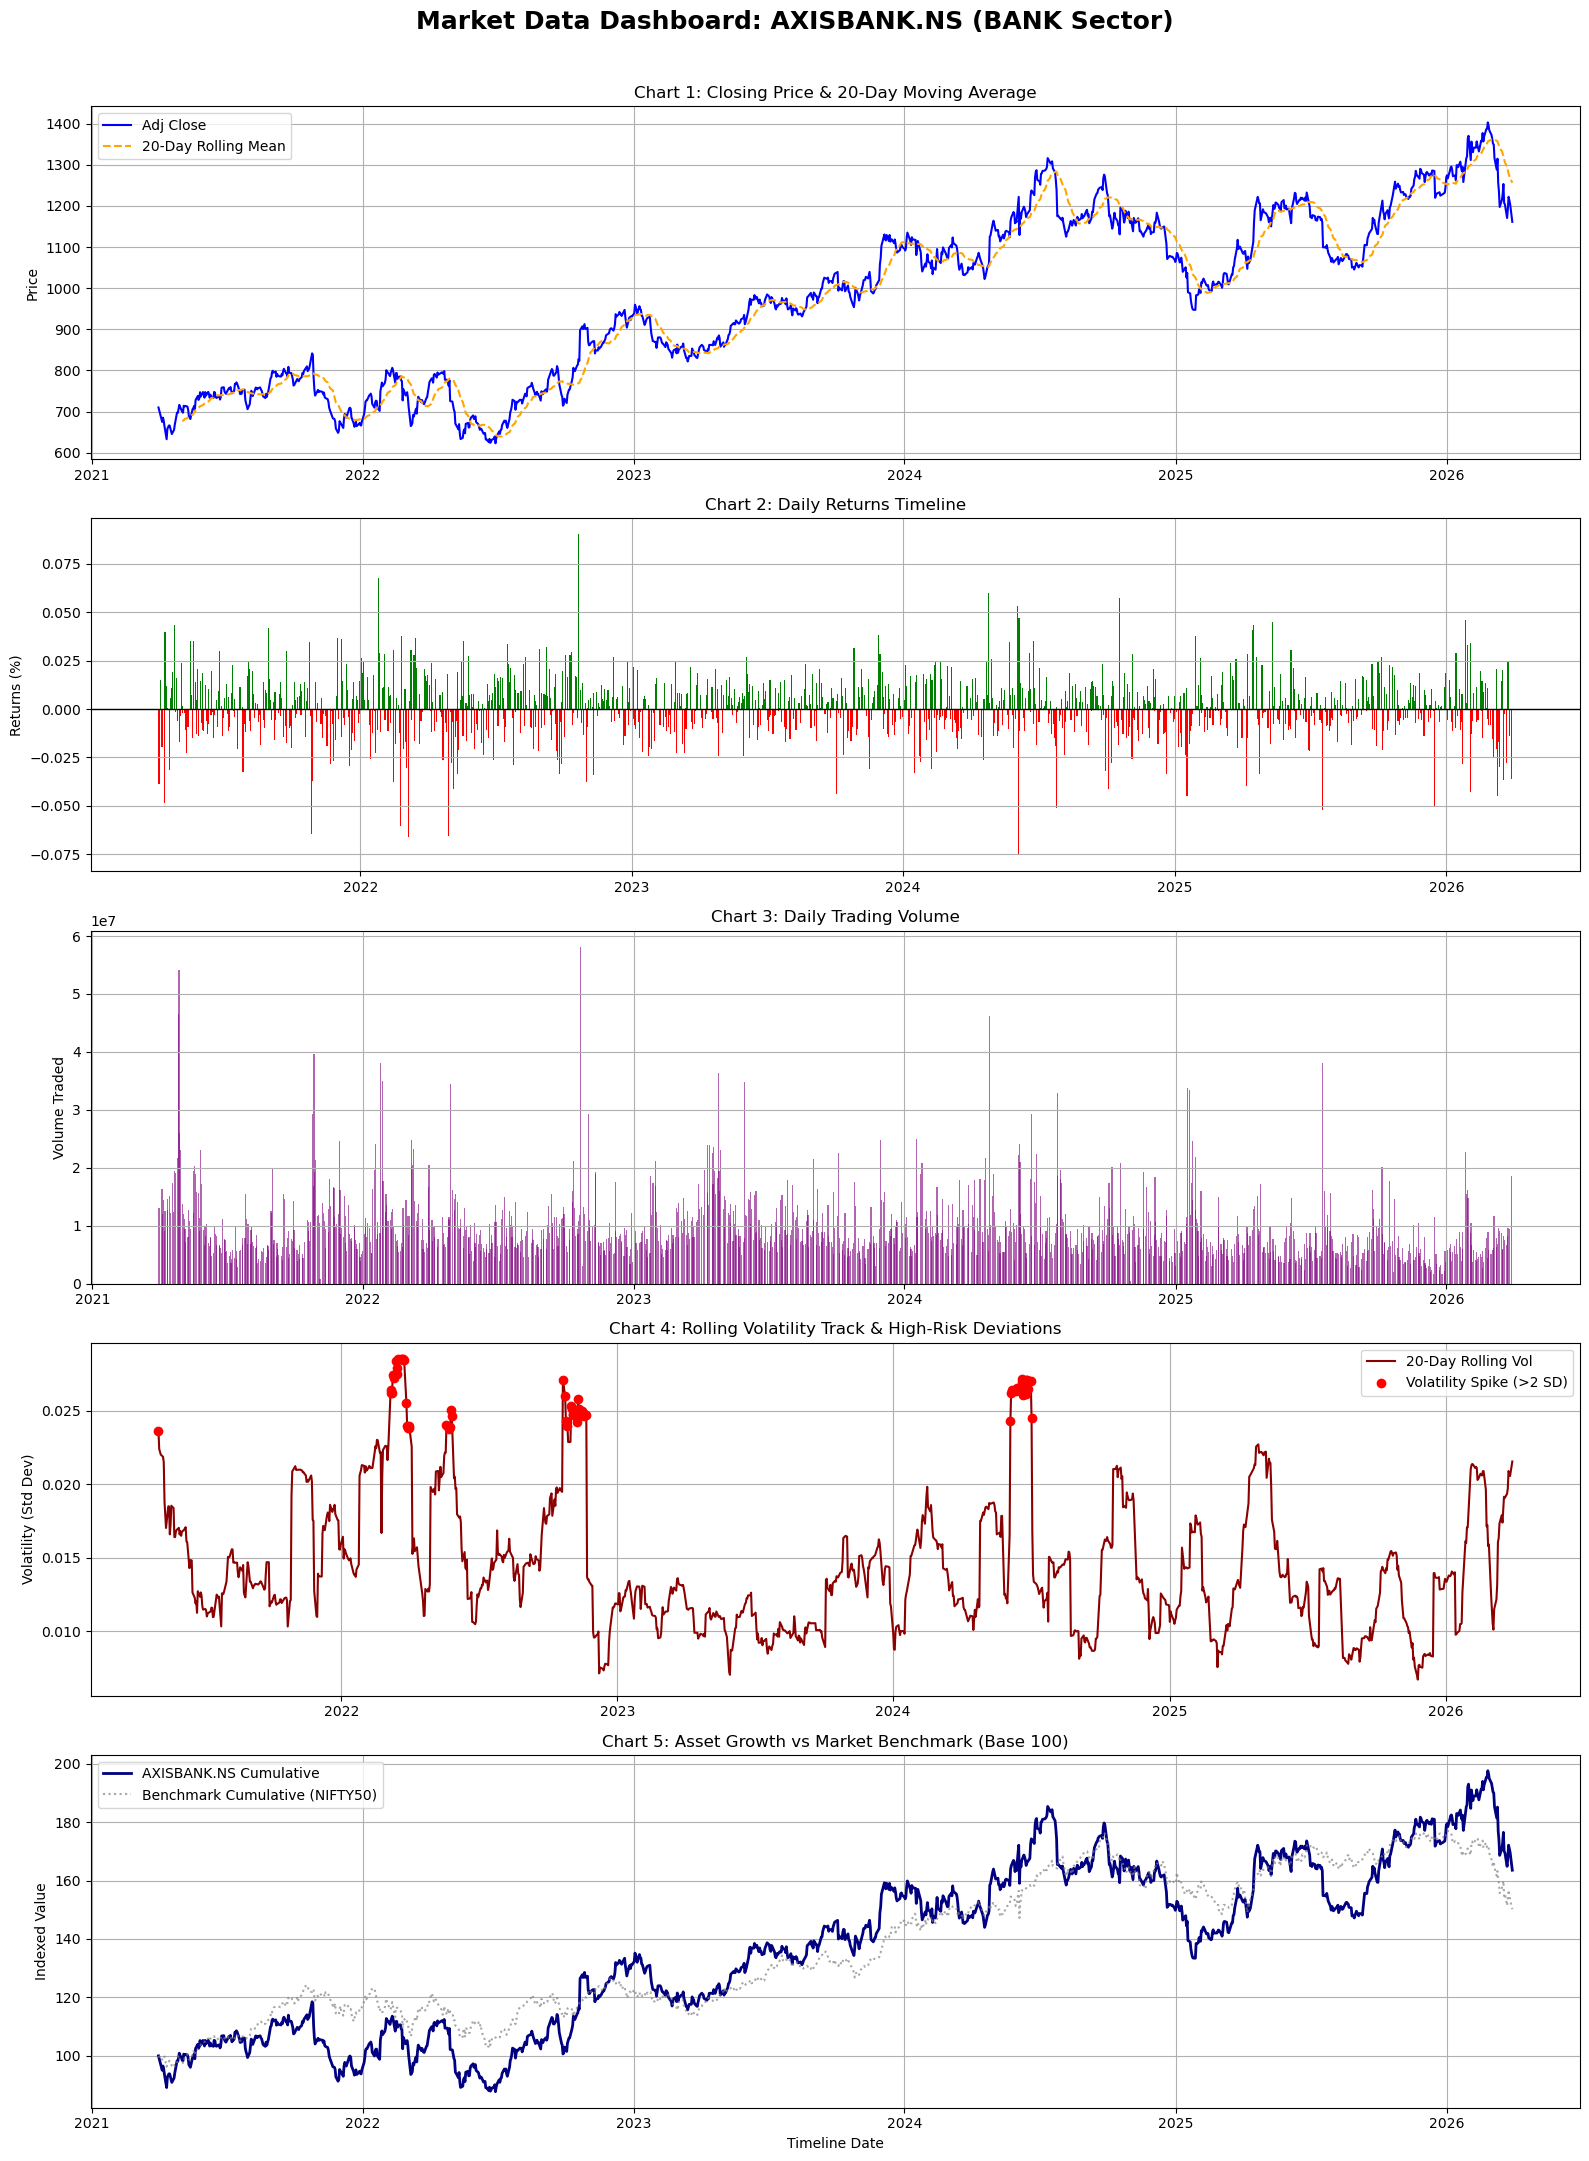

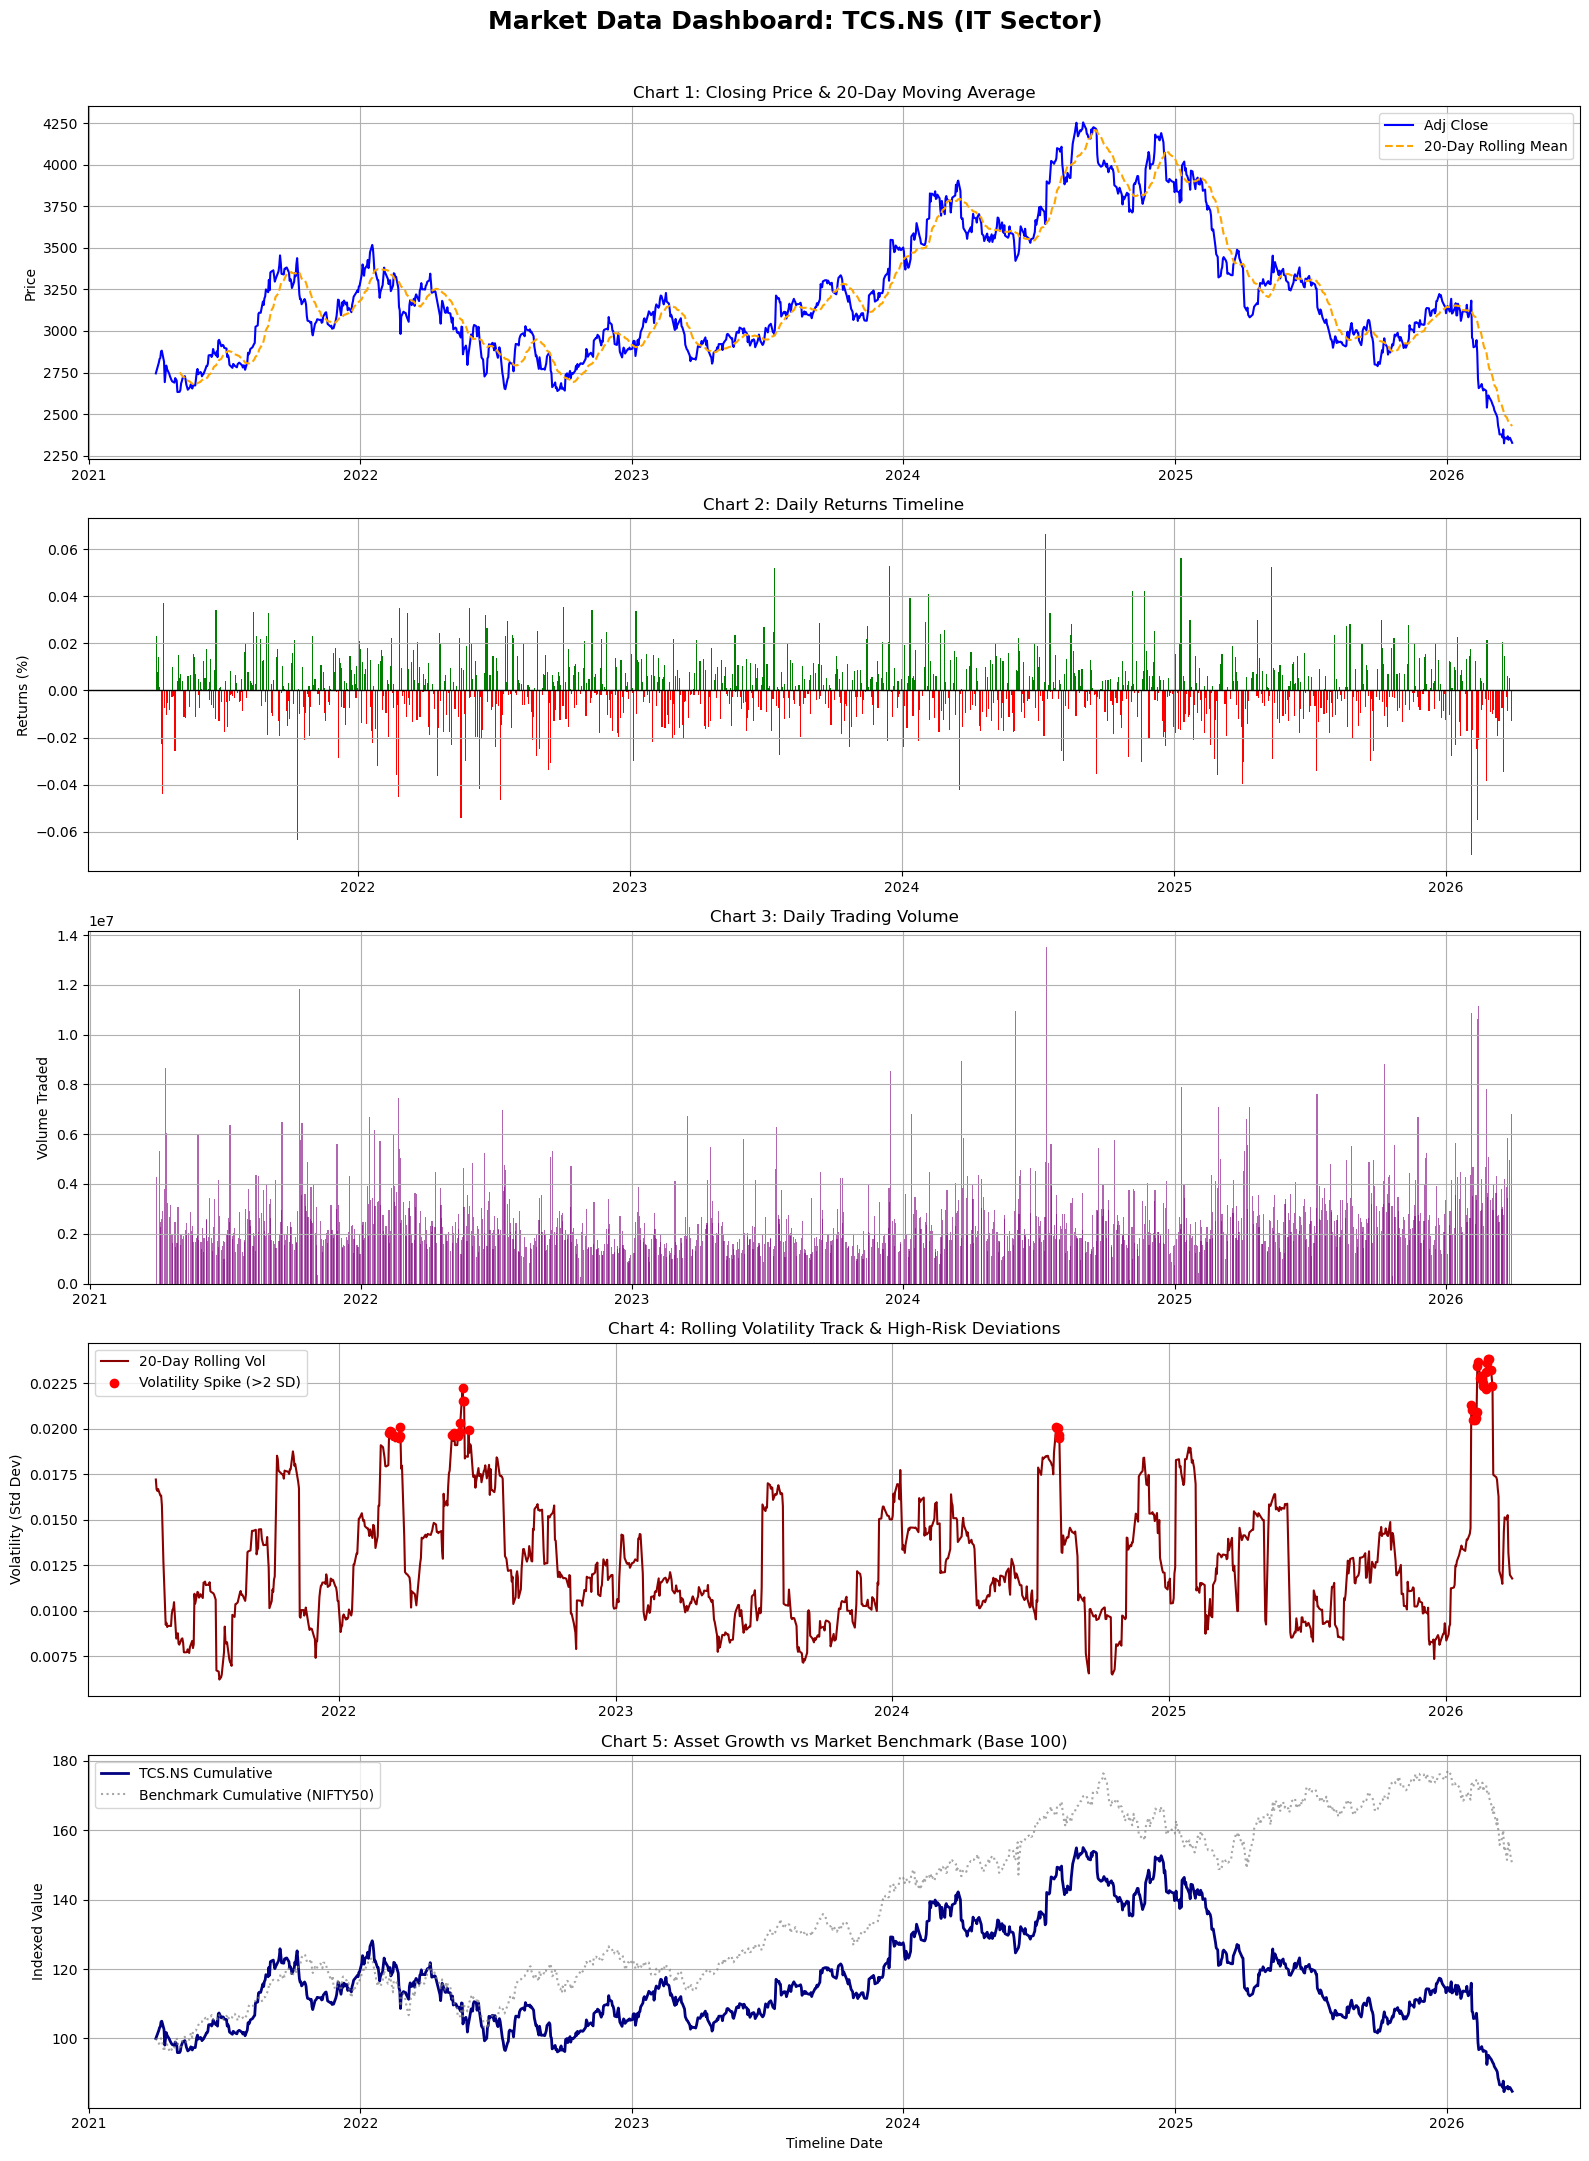

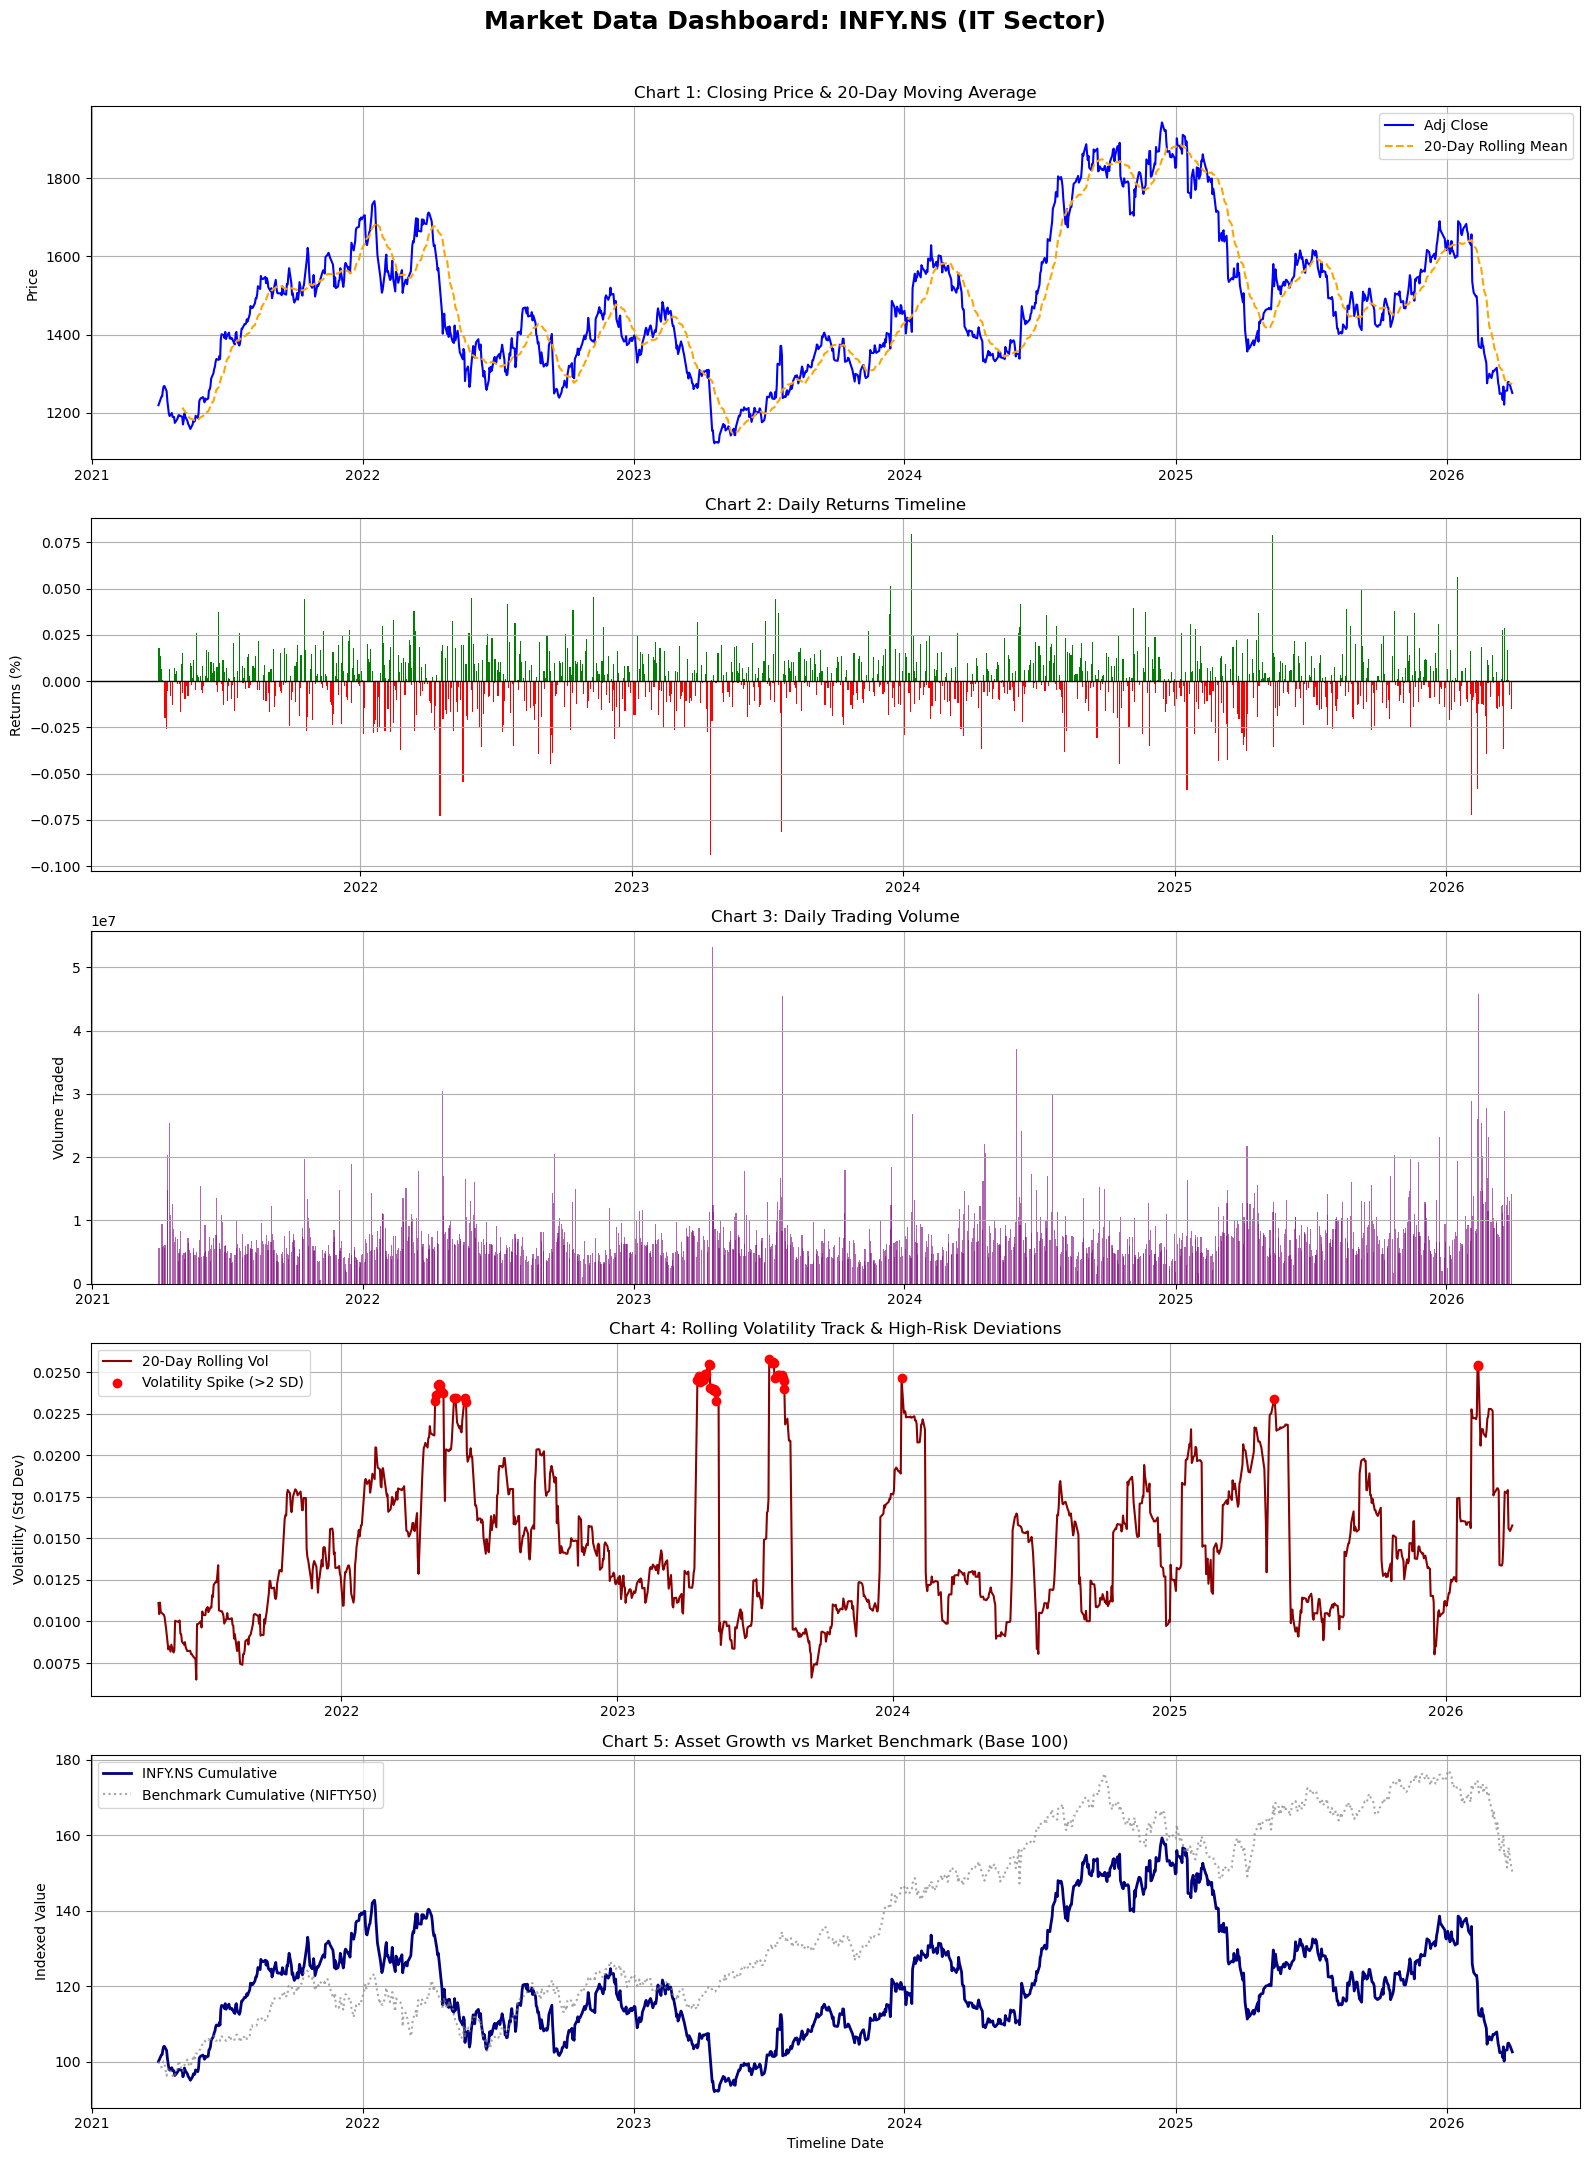

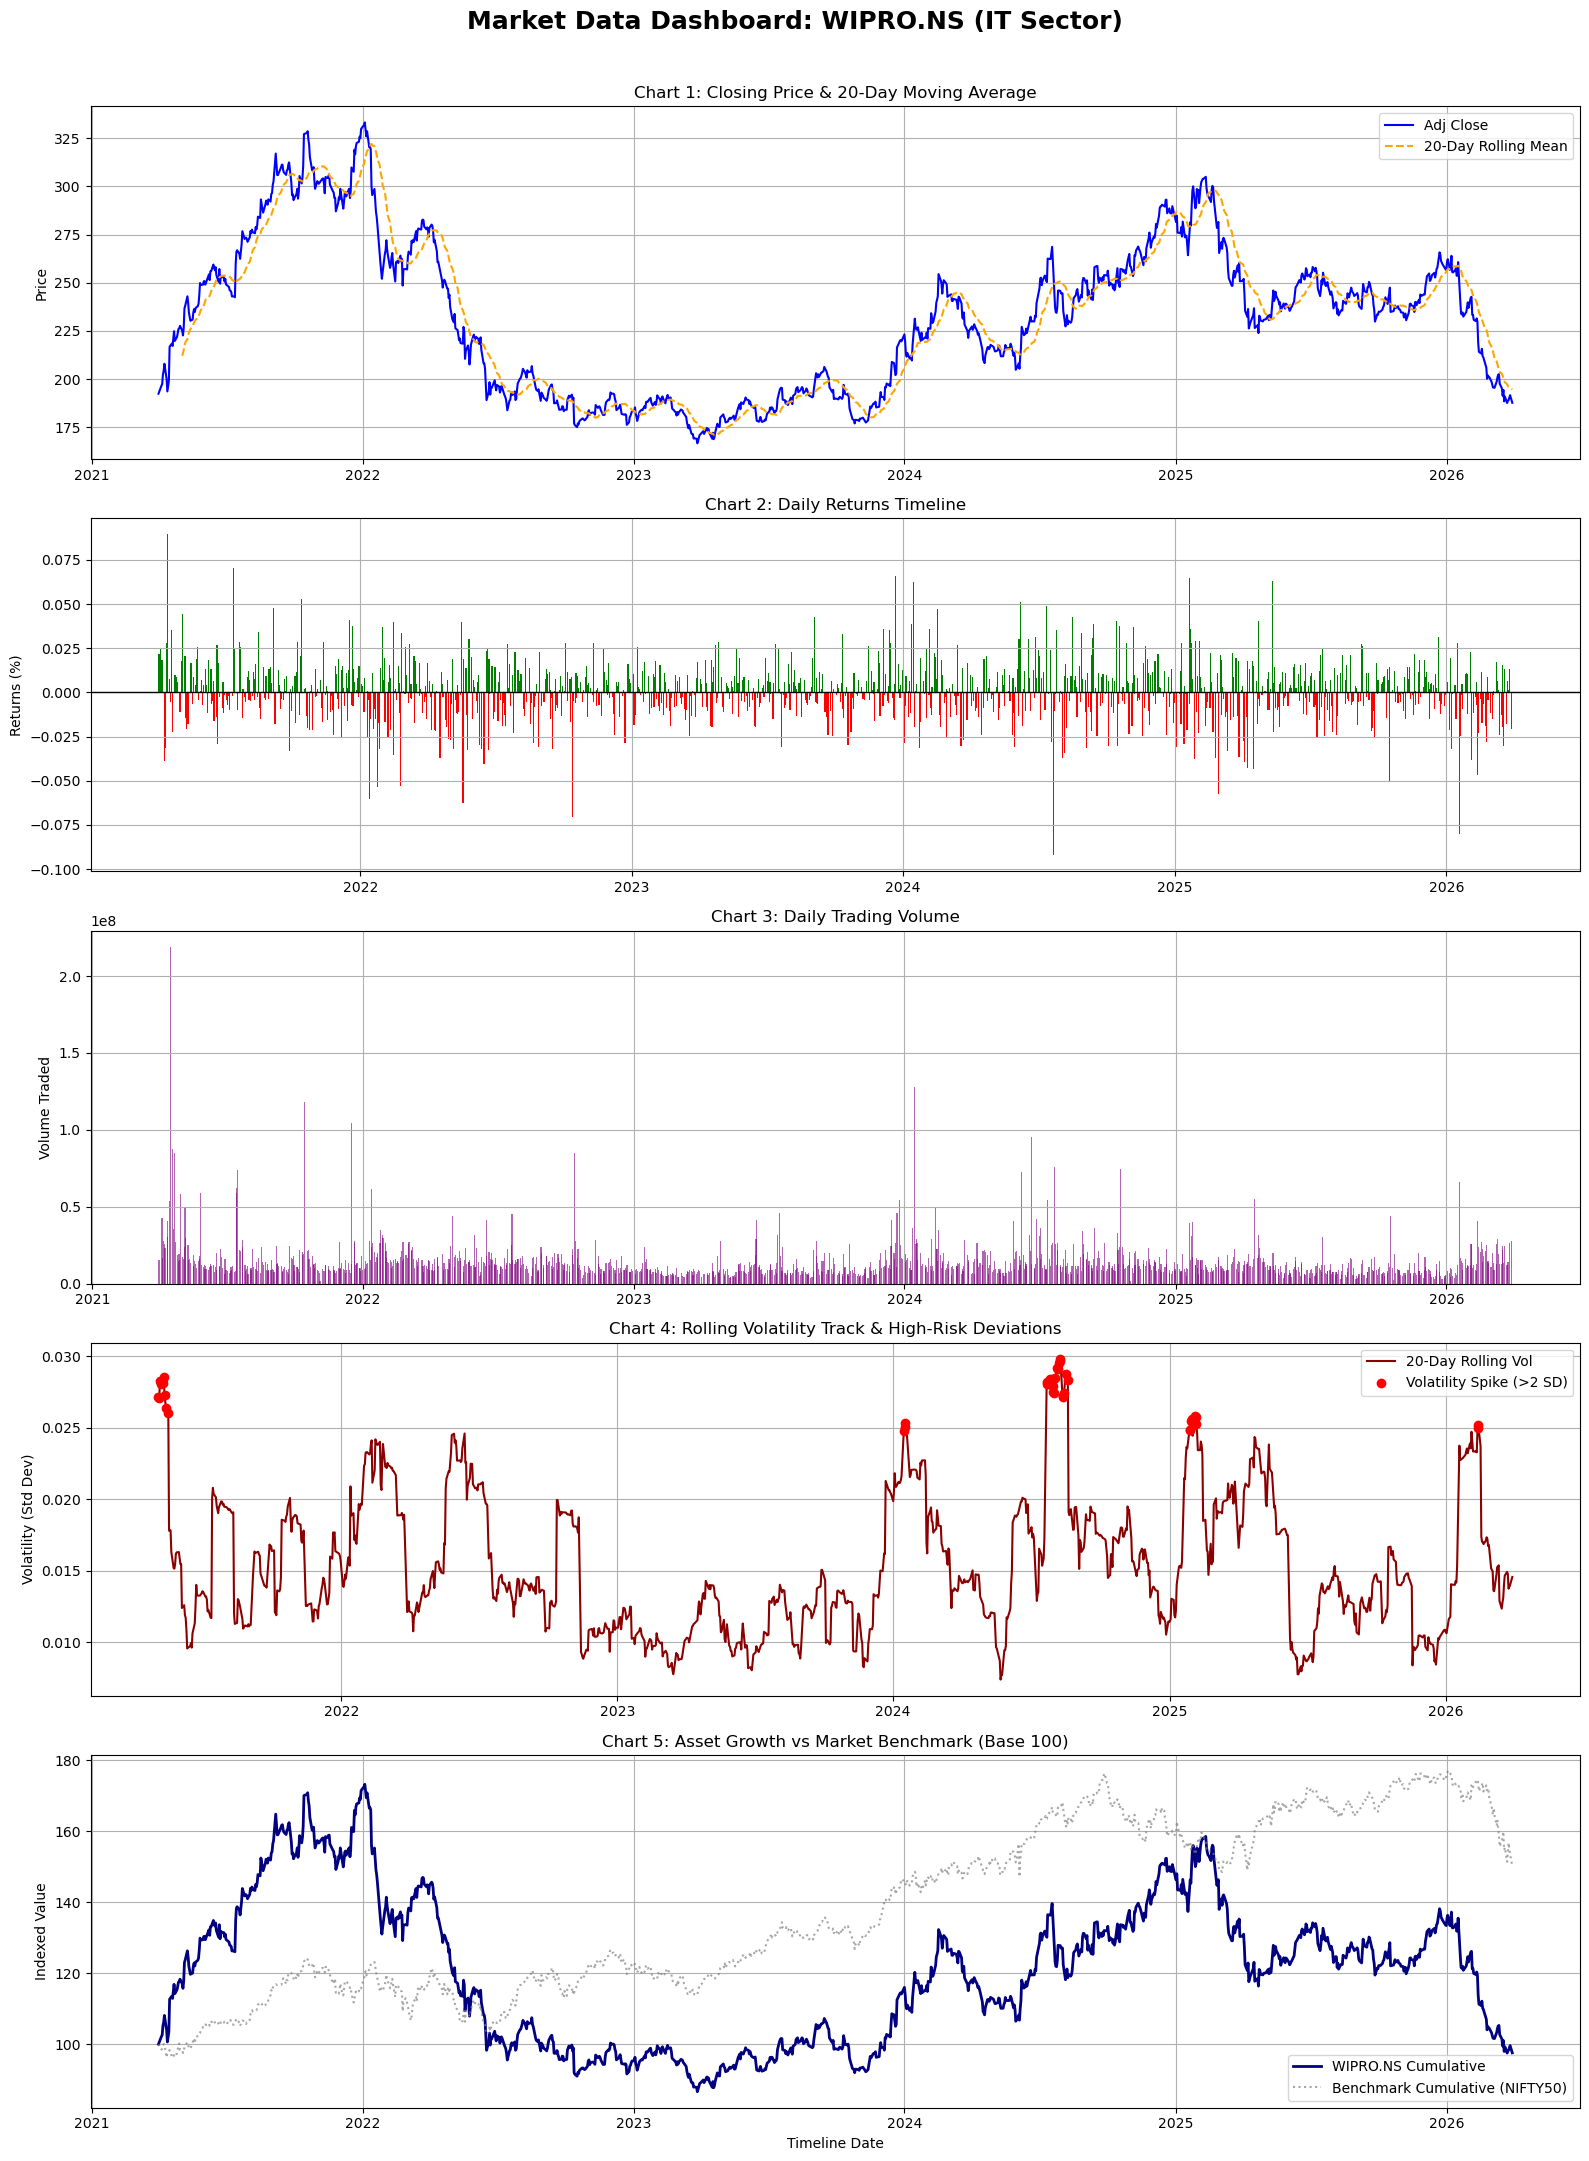

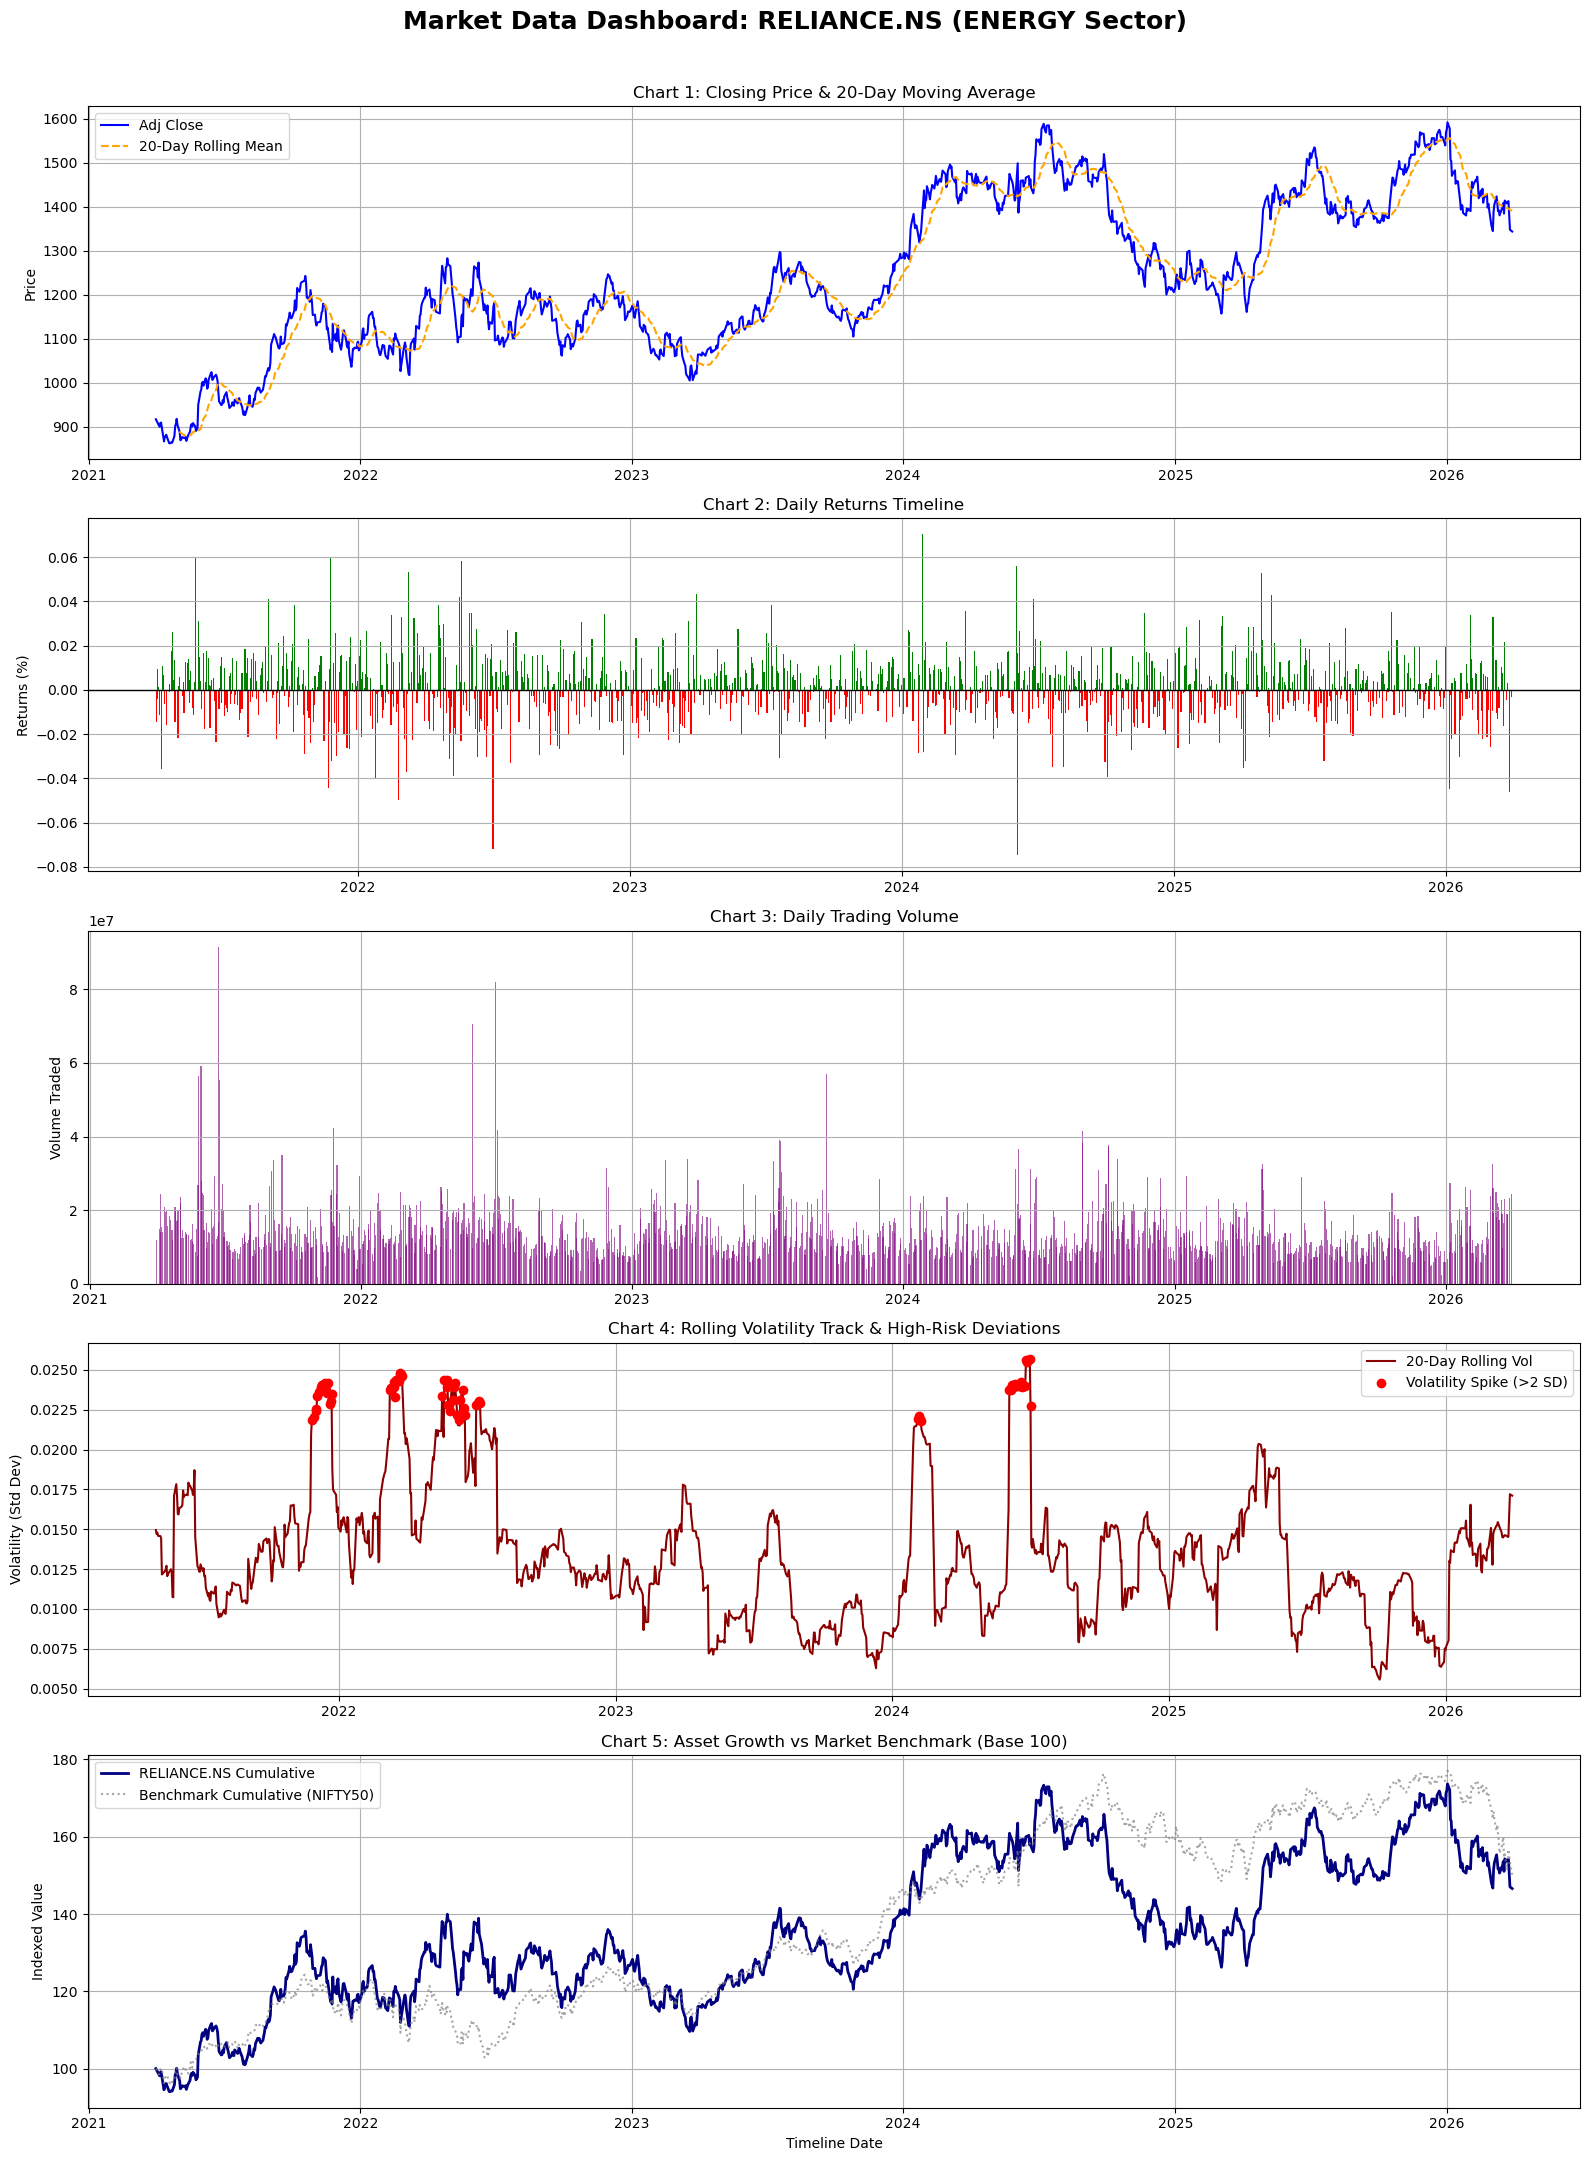

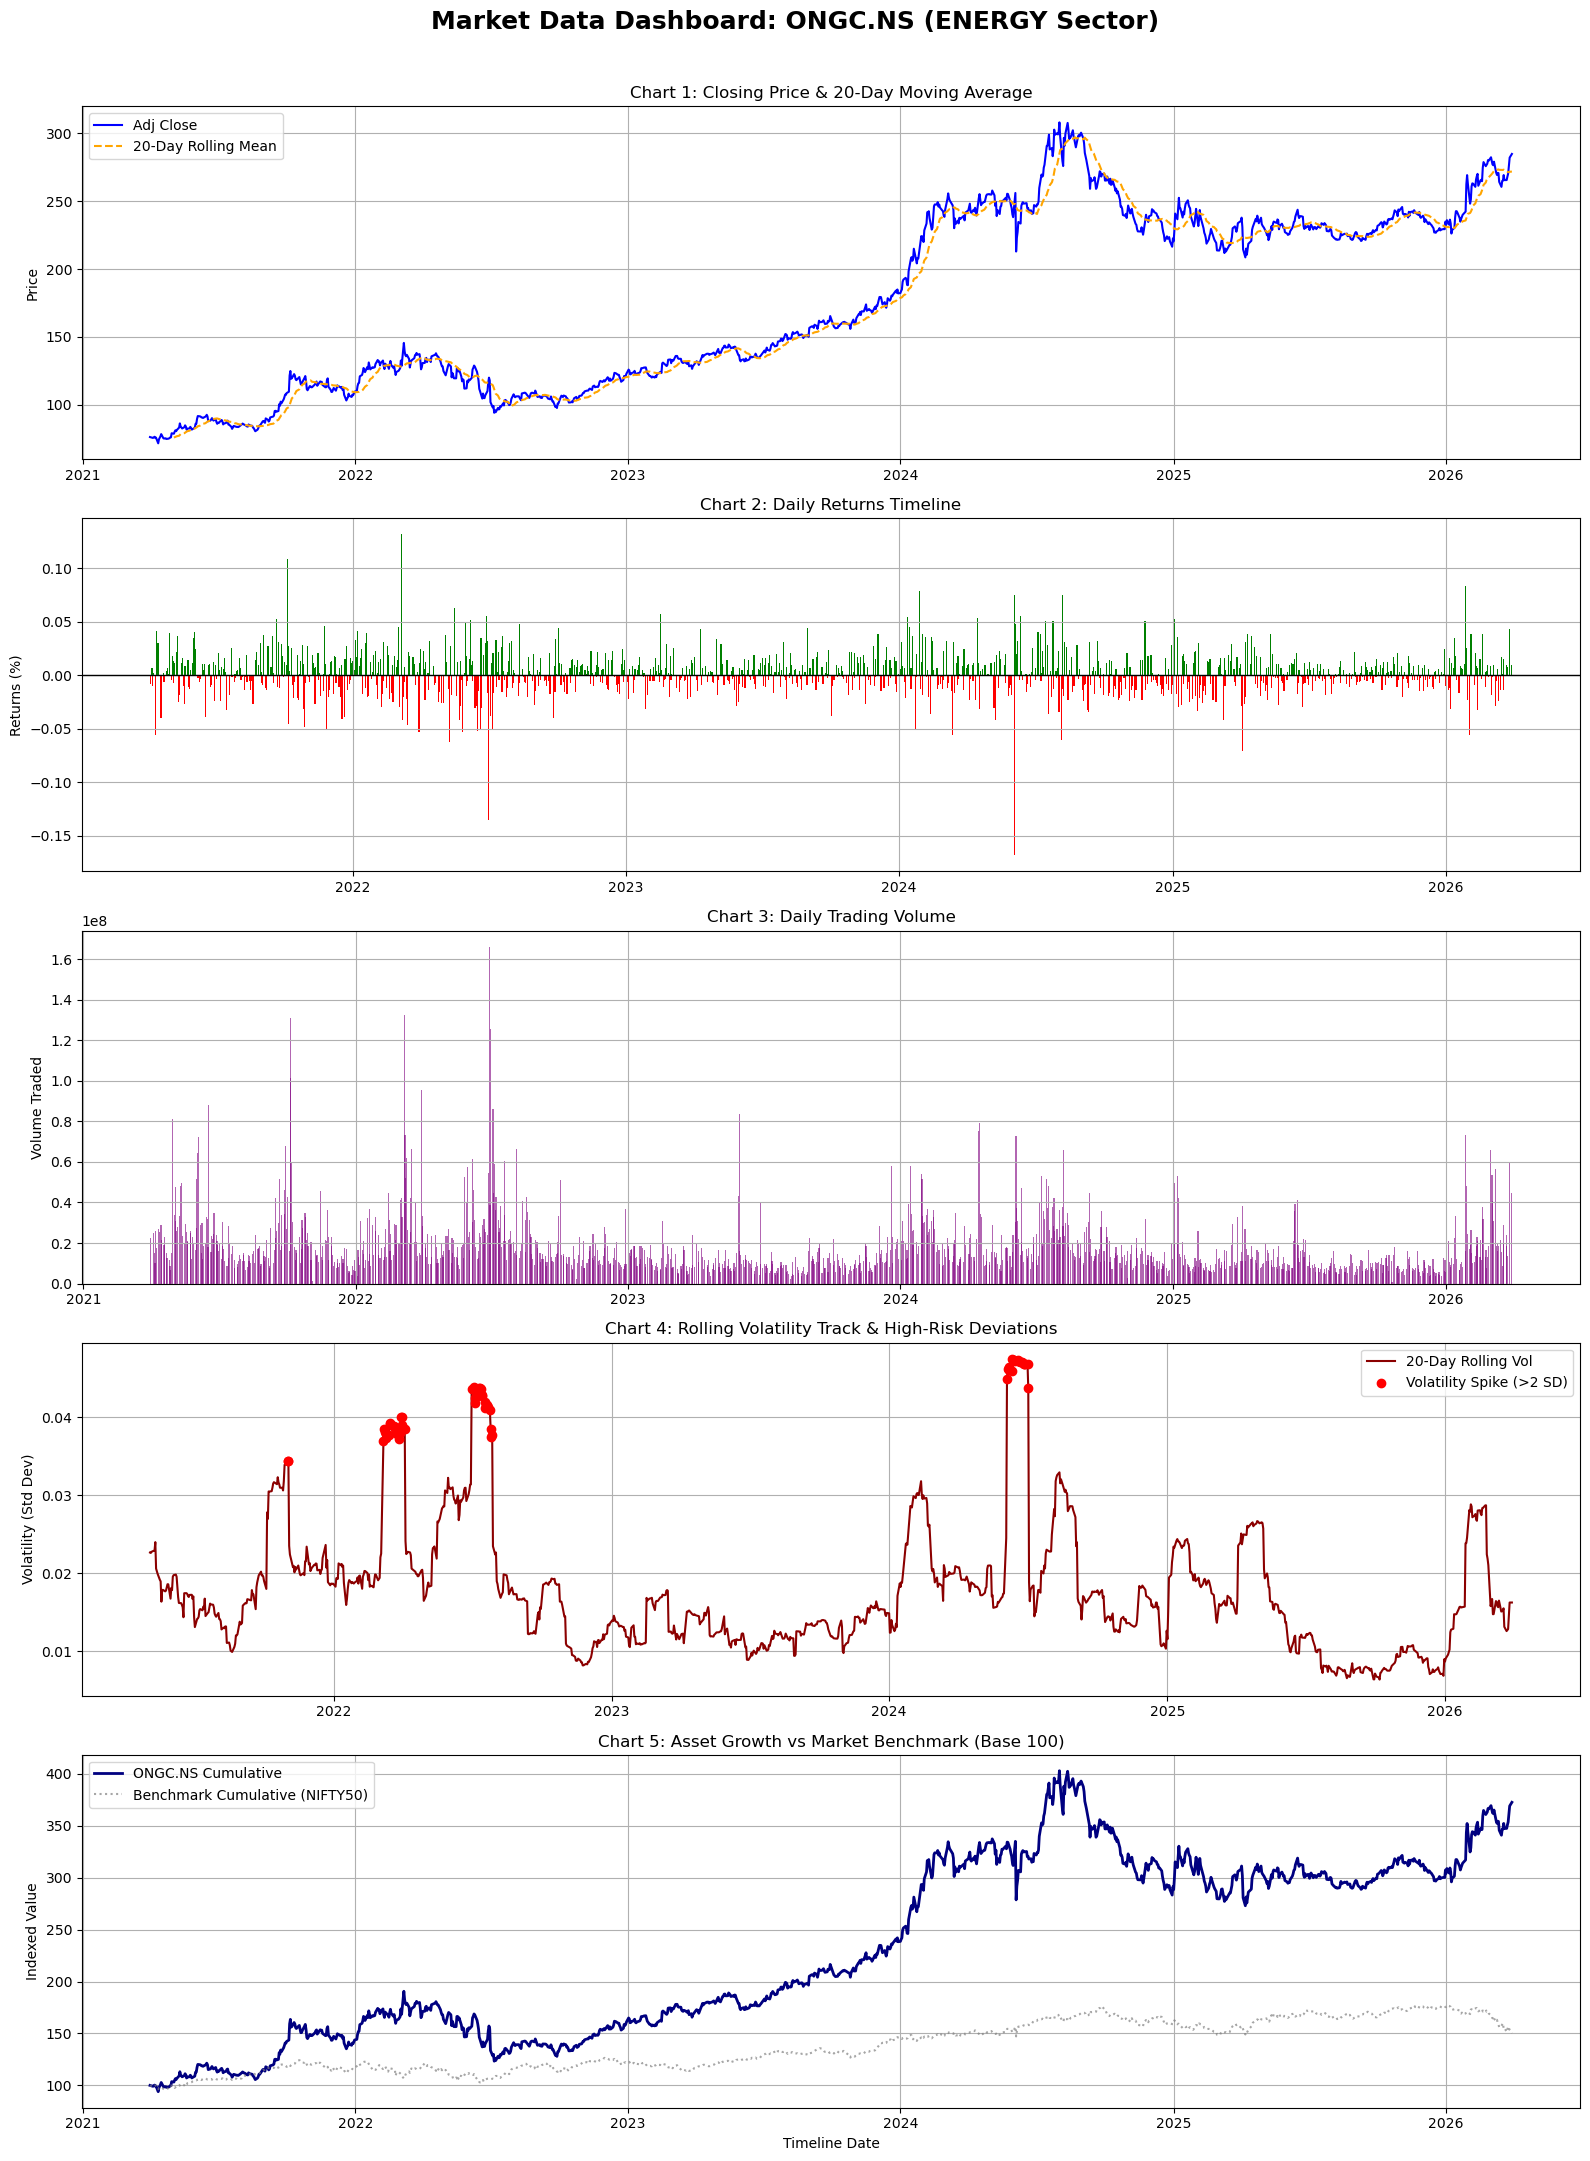

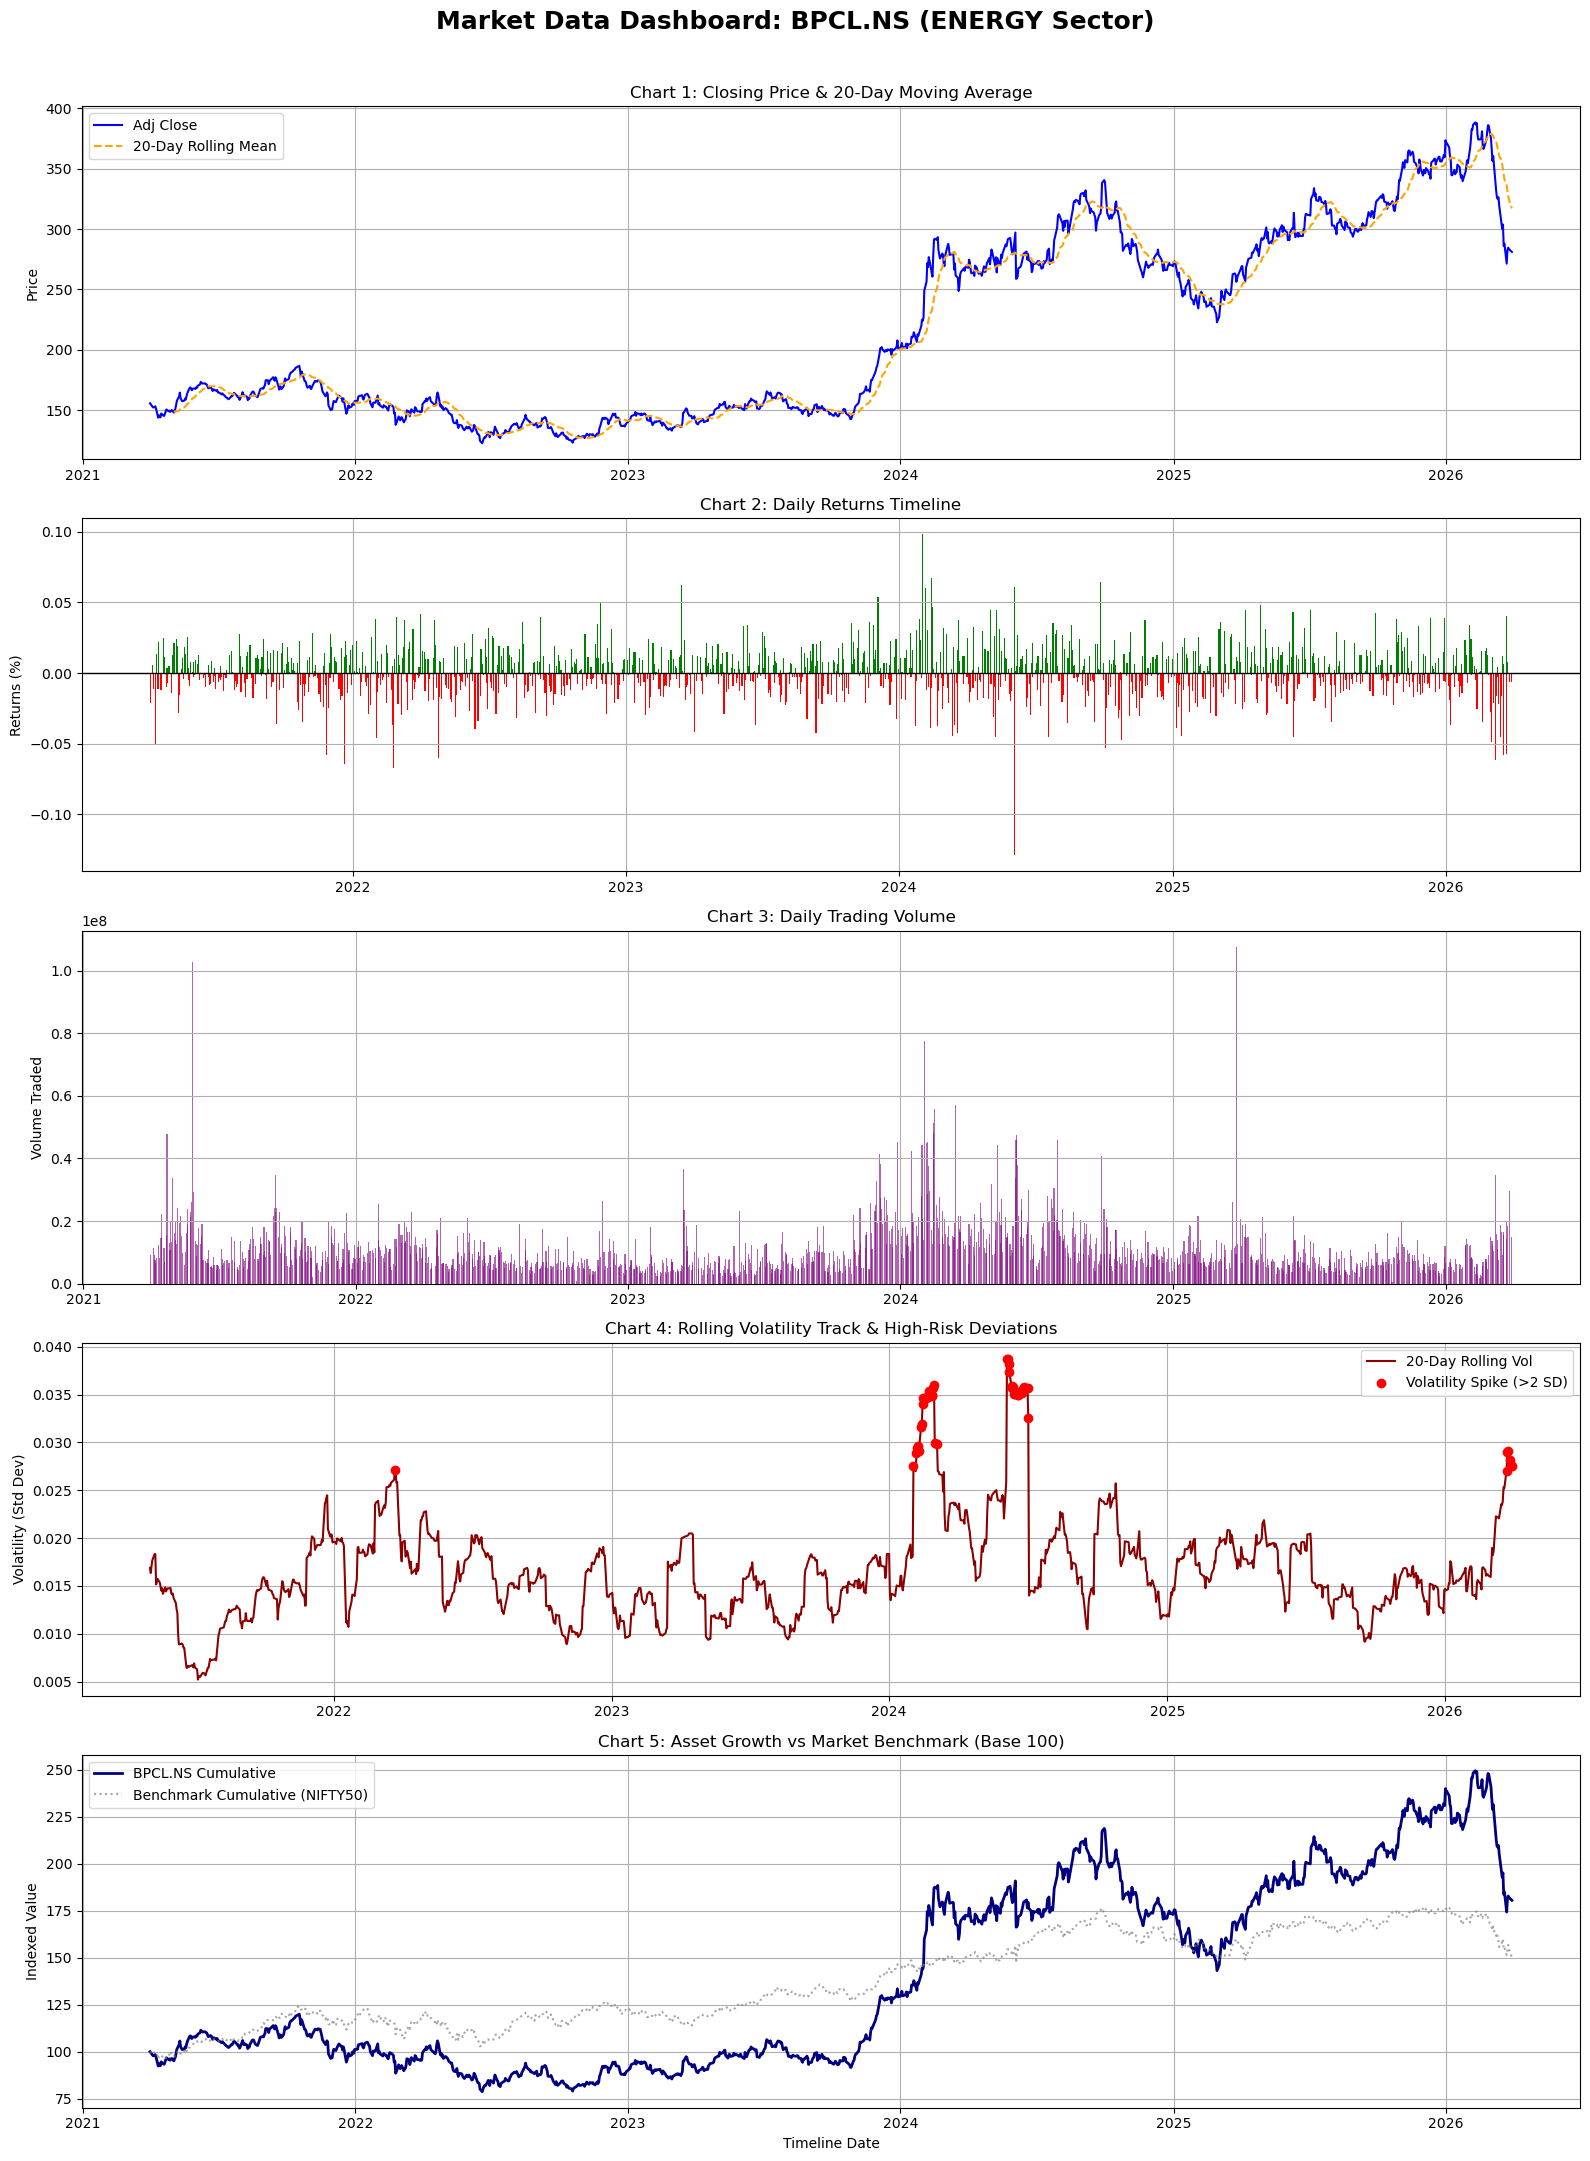

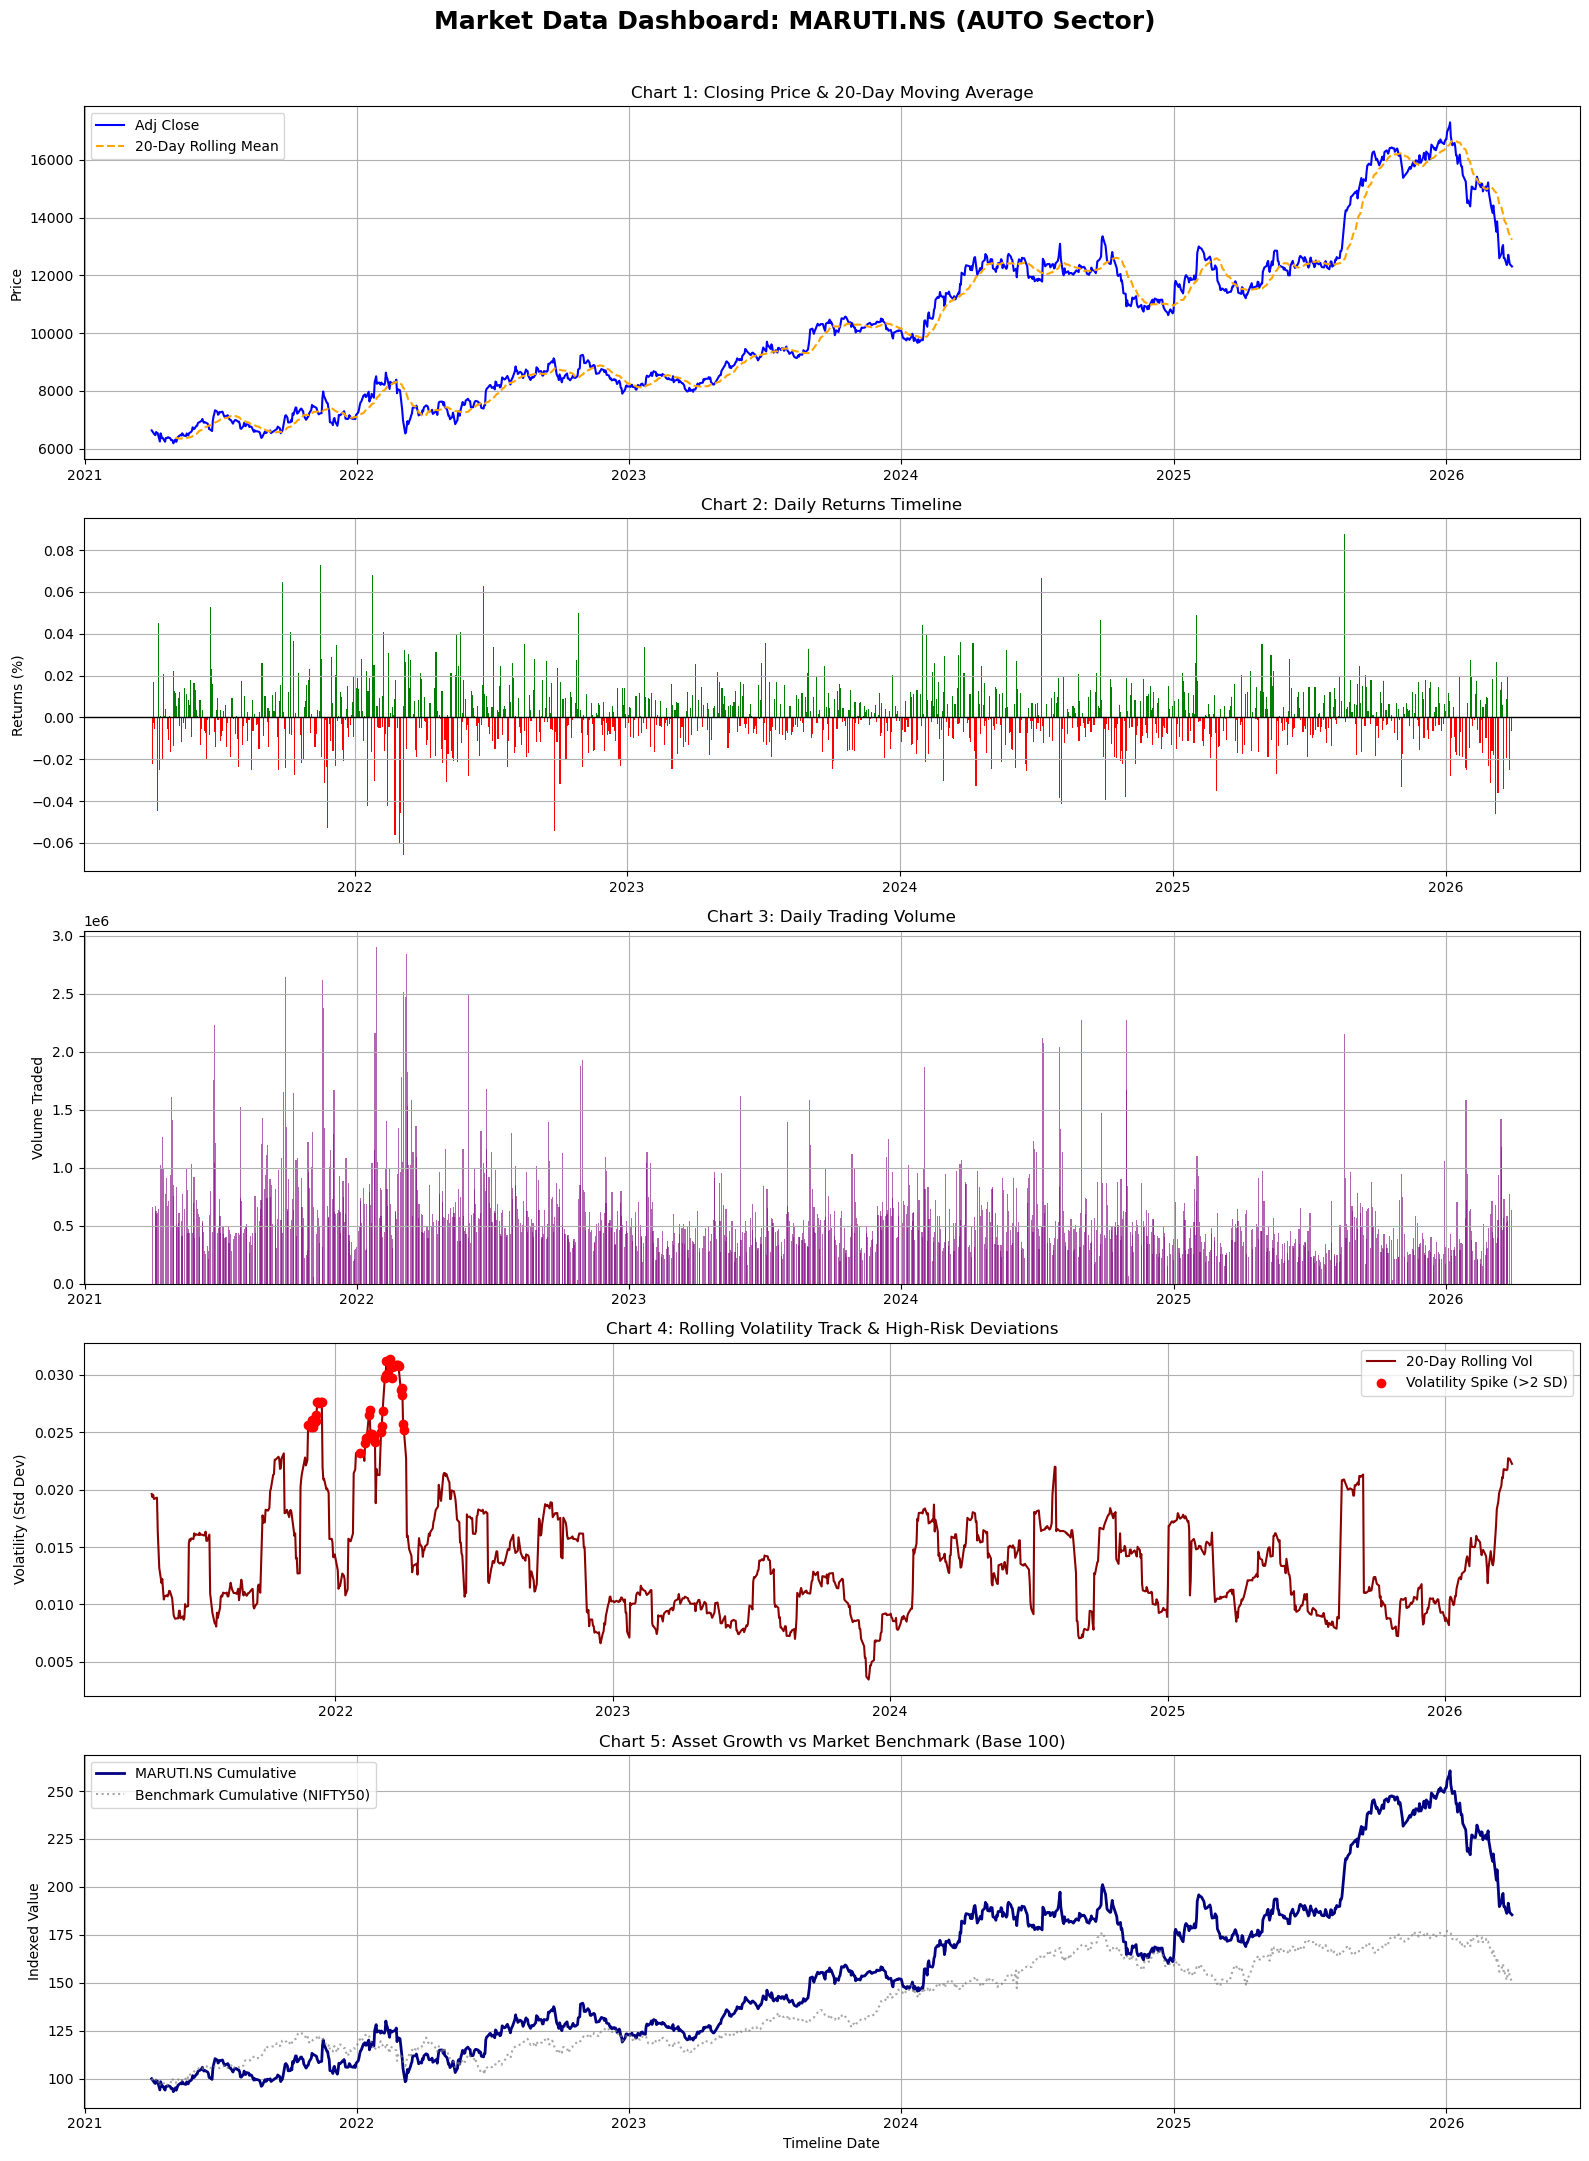

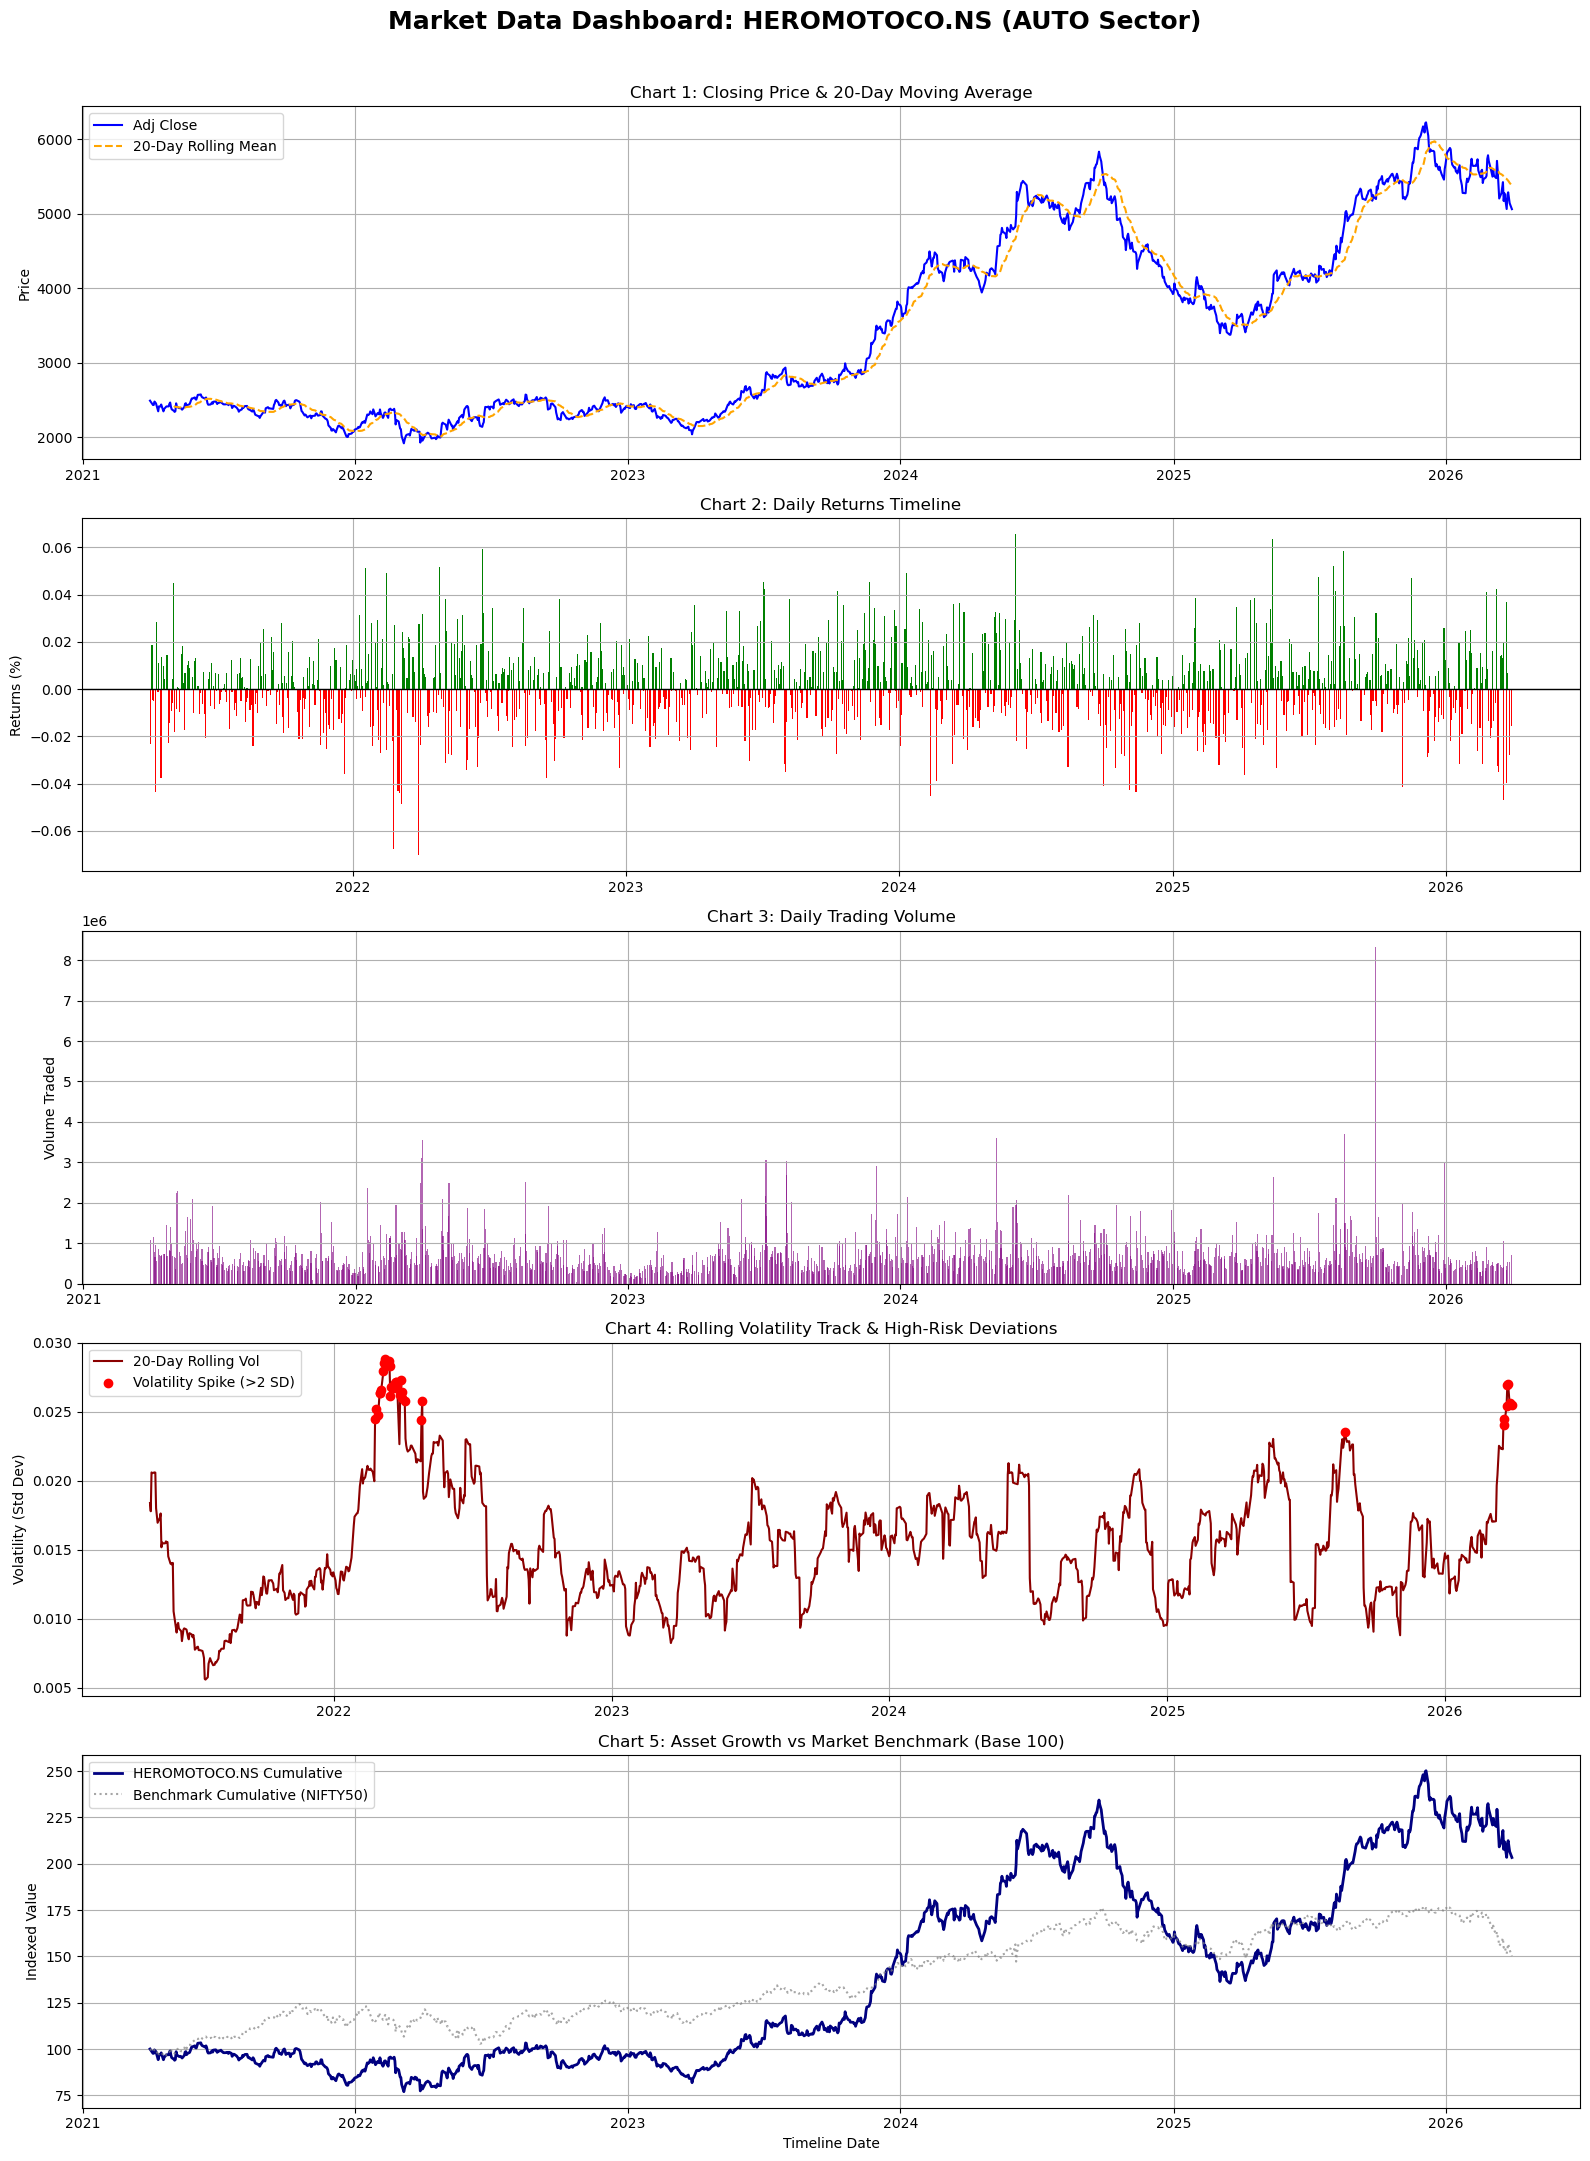

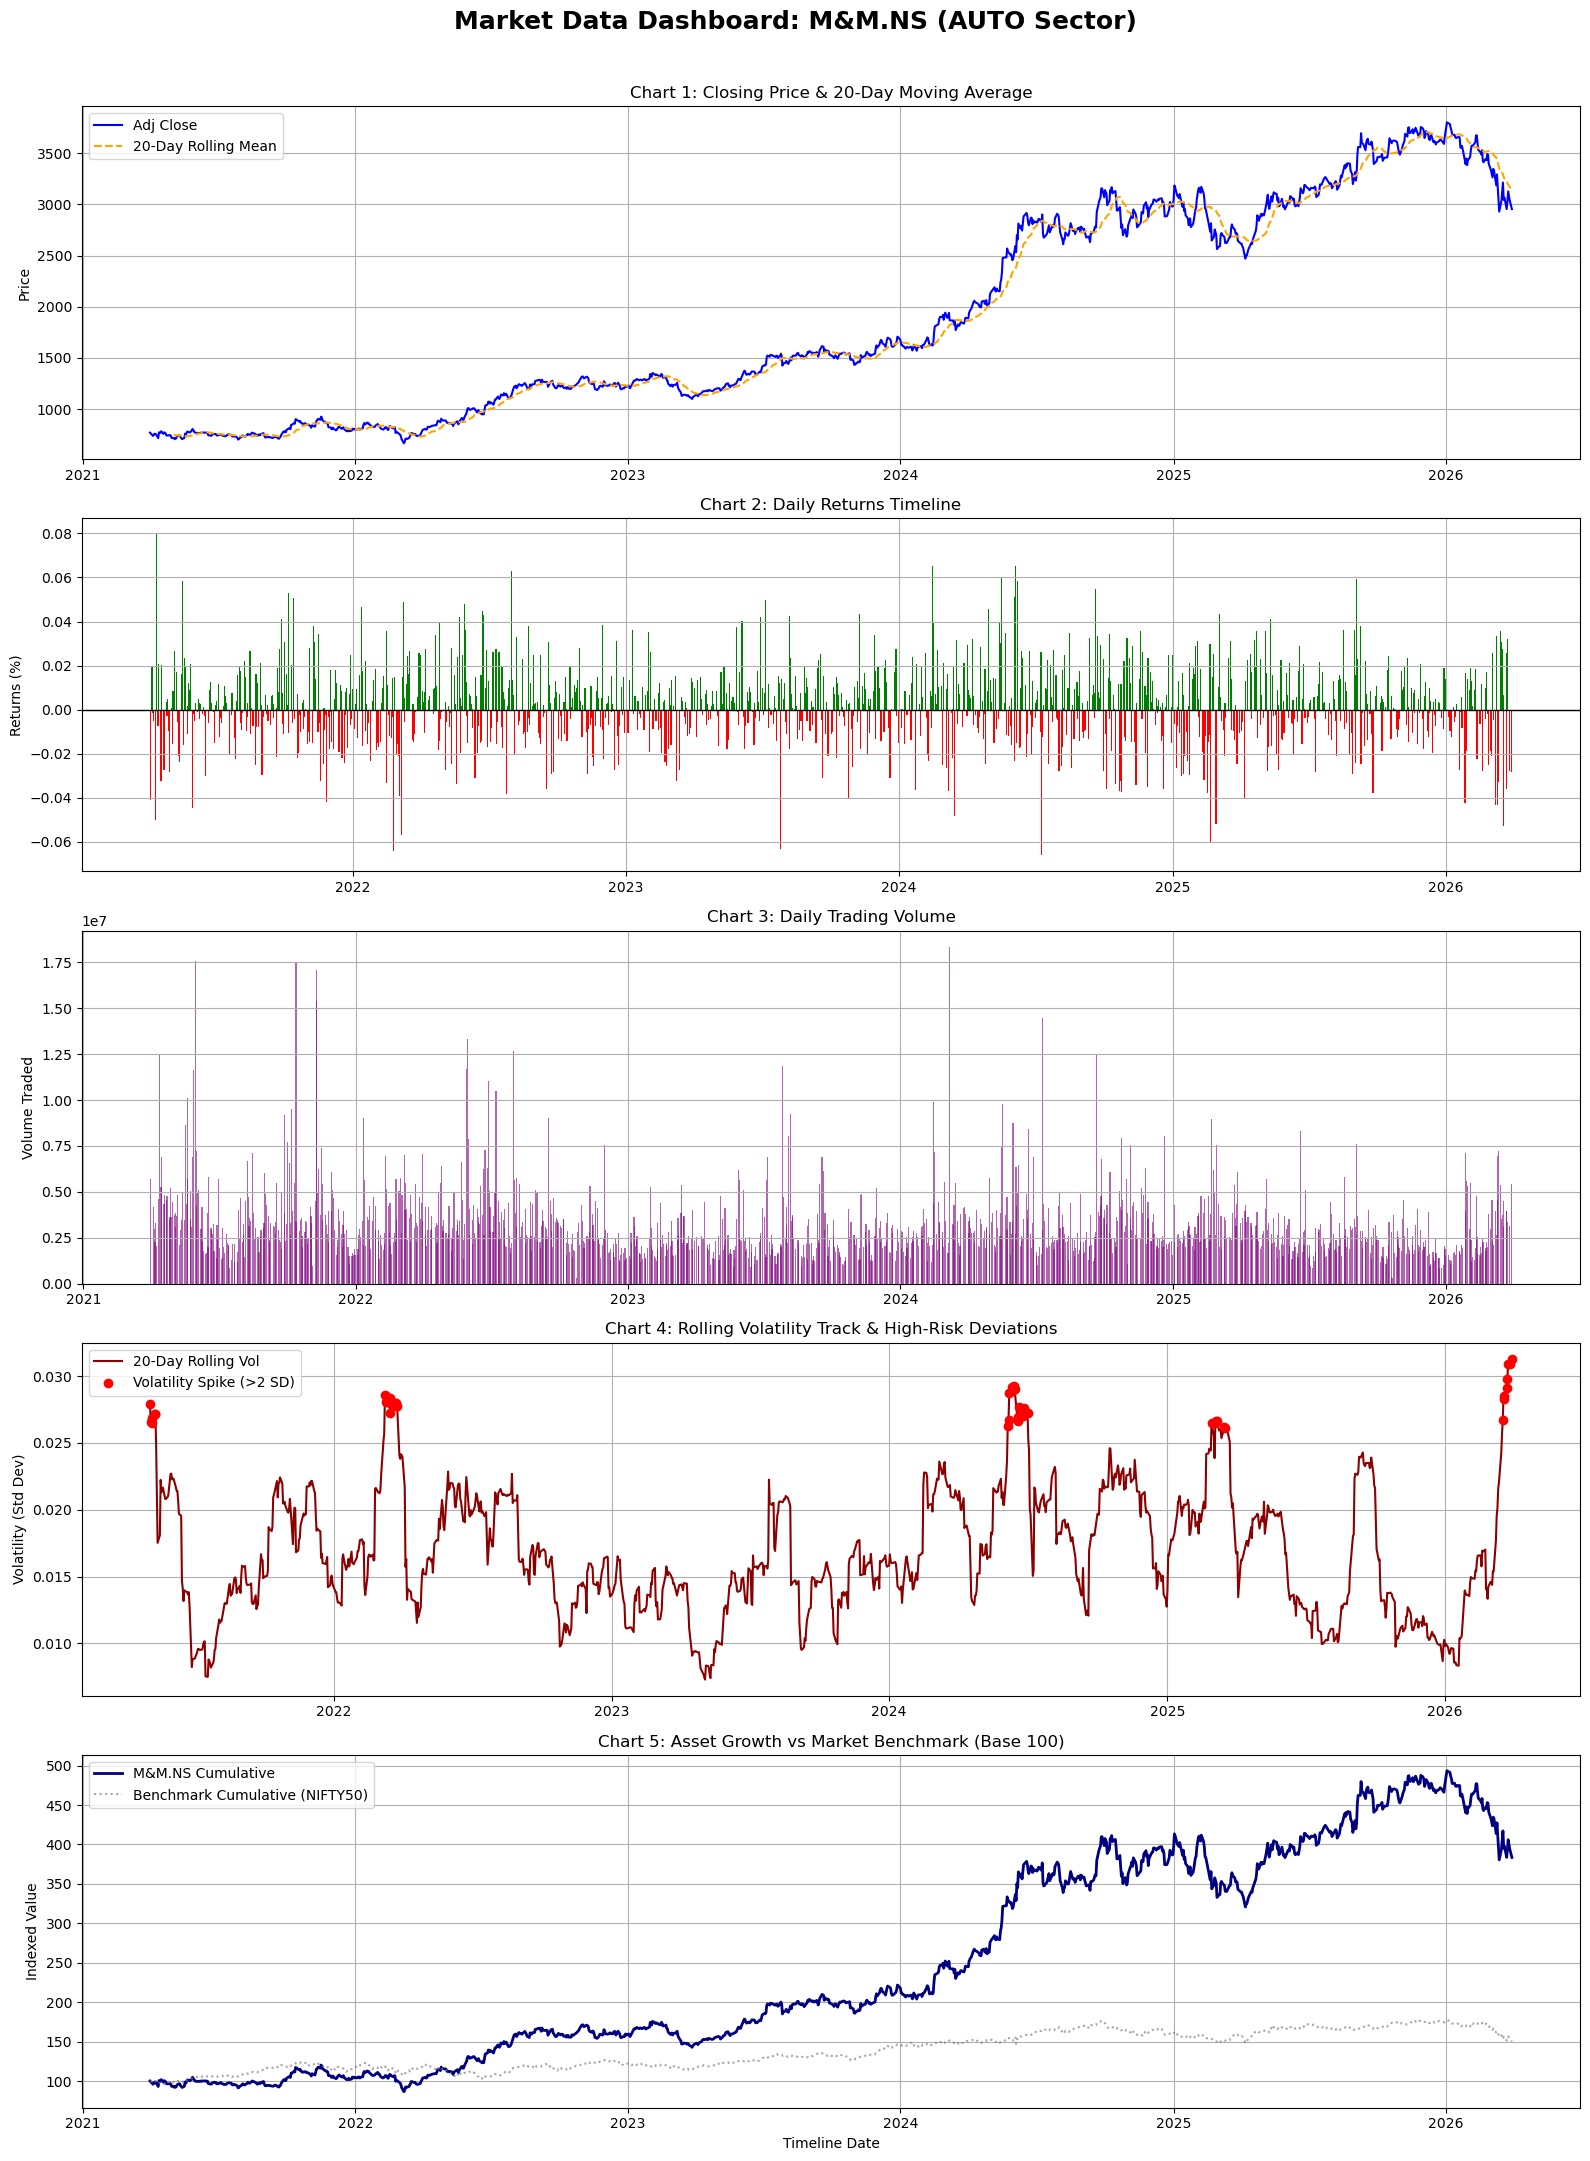

In [10]:
for ticker in tickers:
    adj_close = aligned_df[f'{ticker}_Adj Close']
    close = aligned_df[f'{ticker}_Close']
    volume = aligned_df[f'{ticker}_Volume']
    bench_close = aligned_df['Benchmark']
    
    # Derived Metrics
    daily_returns = adj_close.pct_change()
    cum_returns = (1 + daily_returns.fillna(0)).cumprod() * 100
    bench_returns = bench_close.pct_change()
    bench_cum = (1 + bench_returns.fillna(0)).cumprod() * 100
    
    rolling_mean_20 = adj_close.rolling(20).mean()
    rolling_vol_20 = daily_returns.rolling(20).std()
    
    # Volatility Spike Check (2 SD above the mean)
    vol_mean = rolling_vol_20.mean()
    vol_std = rolling_vol_20.std()
    spike_threshold = vol_mean + (2 * vol_std)
    spikes = rolling_vol_20[rolling_vol_20 > spike_threshold]
    
    # Setup 5-subplot Grid Layout
    fig = plt.figure(figsize=(16, 22))
    fig.suptitle(f'Market Data Dashboard: {ticker} ({ticker_sectors[ticker]} Sector)', fontsize=18, fontweight='bold')
    
    # Chart 1: Close Price vs 20-Day Rolling Mean
    ax1 = plt.subplot(5, 1, 1)
    ax1.plot(adj_close.index, adj_close, label='Adj Close', color='blue')
    ax1.plot(rolling_mean_20.index, rolling_mean_20, label='20-Day Rolling Mean', color='orange', linestyle='--')
    ax1.set_title("Chart 1: Closing Price & 20-Day Moving Average")
    ax1.set_ylabel("Price")
    ax1.legend()
    ax1.grid(True)
    
    # Chart 2: Daily Returns Bar Chart
    ax2 = plt.subplot(5, 1, 2)
    colors = ['green' if x >= 0 else 'red' for x in daily_returns.fillna(0)]
    ax2.bar(daily_returns.index, daily_returns, color=colors, width=1.5)
    ax2.axhline(0, color='black', linewidth=1)
    ax2.set_title("Chart 2: Daily Returns Timeline")
    ax2.set_ylabel("Returns (%)")
    ax2.grid(True)
    
    # Chart 3: Volume Bar Chart
    ax3 = plt.subplot(5, 1, 3)
    ax3.bar(volume.index, volume, color='purple', alpha=0.6, width=1.5)
    ax3.set_title("Chart 3: Daily Trading Volume")
    ax3.set_ylabel("Volume Traded")
    ax3.grid(True)
    
    # Chart 4: 20-Day Rolling Volatility with Spikes Marked
    ax4 = plt.subplot(5, 1, 4)
    ax4.plot(rolling_vol_20.index, rolling_vol_20, color='darkred', label='20-Day Rolling Vol')
    ax4.scatter(spikes.index, spikes, color='red', label='Volatility Spike (>2 SD)', zorder=5)
    ax4.set_title("Chart 4: Rolling Volatility Track & High-Risk Deviations")
    ax4.set_ylabel("Volatility (Std Dev)")
    ax4.legend()
    ax4.grid(True)
    
    # Chart 5: Cumulative Returns vs Benchmark
    ax5 = plt.subplot(5, 1, 5)
    ax5.plot(cum_returns.index, cum_returns, label=f'{ticker} Cumulative', color='navy', linewidth=2)
    ax5.plot(bench_cum.index, bench_cum, label='Benchmark Cumulative (NIFTY50)', color='grey', alpha=0.7, linestyle=':')
    ax5.set_title("Chart 5: Asset Growth vs Market Benchmark (Base 100)")
    ax5.set_ylabel("Indexed Value")
    ax5.set_xlabel("Timeline Date")
    ax5.legend()
    ax5.grid(True)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.savefig(f"{ticker}_dashboard.png")
    plt.show()
    # Save Image Deliverable
    
    plt.close()

Correlation Analysis

Min Off-Diagonal Correlation Coefficient: 0.1308
Max Off-Diagonal Correlation Coefficient: 0.7092
Mean Off-Diagonal Correlation Coefficient: 0.2933

Best Standalone Diversifier: ENERGY_ONGC.NS
Lowest Average Correlation with Rest: 0.2095

Redundant Asset Allocations (>0.80): 0 pairs found.
Optimal Structural Diversifiers (<0.20): 14 pairs found.


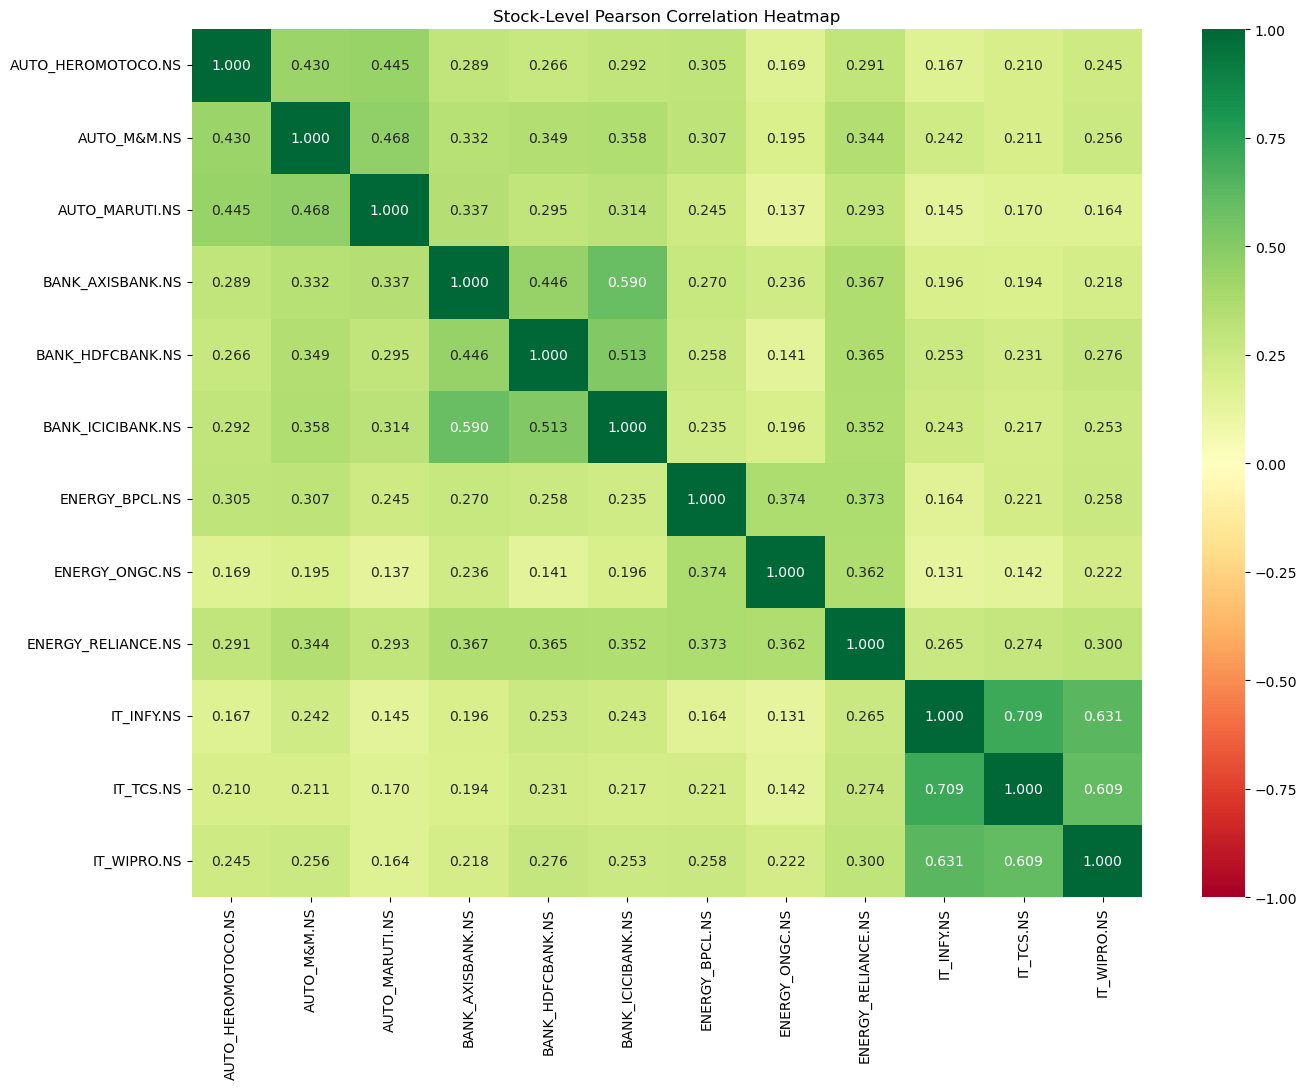

/var/folders/2r/jzh2xr512j56xnw_czmrsylh0000gn/T/ipykernel_55664/4218435427.py:63: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  sector_corr = corr_matrix.groupby(sectors_list).mean().groupby(sectors_list, axis=1).mean()


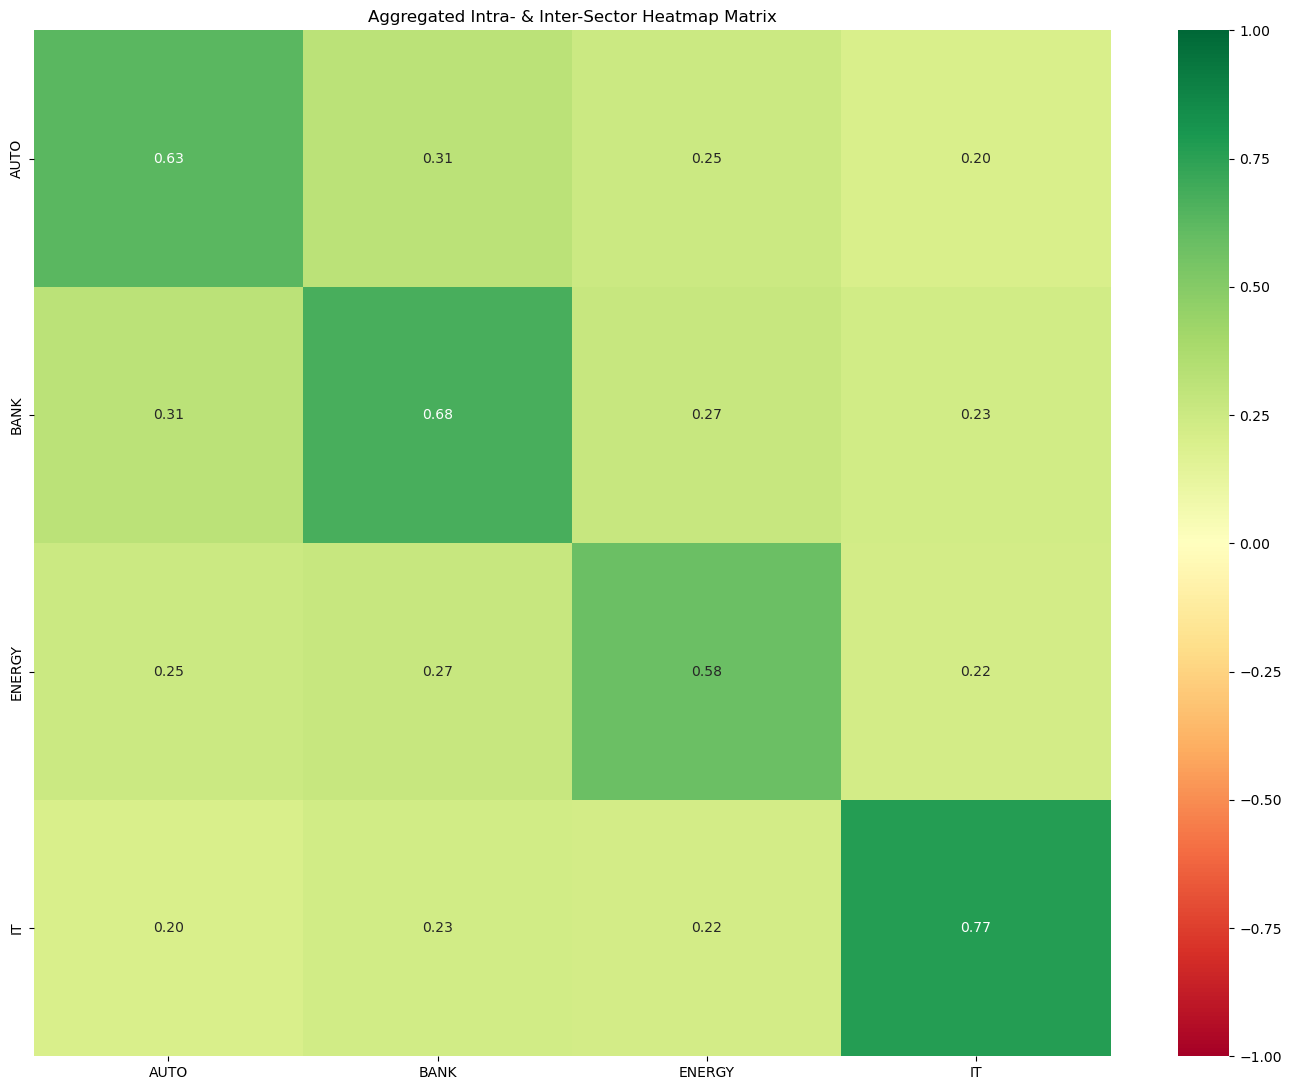

In [14]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Structure daily returns with Sector Prefix labels
returns_dict = {}
for ticker, sector in ticker_sectors.items():
    returns_dict[f"{sector}_{ticker}"] = aligned_df[f'{ticker}_Adj Close'].pct_change()

returns_df = pd.DataFrame(returns_dict).dropna()
returns_df = returns_df.reindex(sorted(returns_df.columns), axis=1)

# 2. Compute Pearson Matrix
corr_matrix = returns_df.corr(method='pearson')

# Extract Off-Diagonal Coefficients
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
all_coefs = upper_tri.stack().values

print(f"Min Off-Diagonal Correlation Coefficient: {all_coefs.min():.4f}")
print(f"Max Off-Diagonal Correlation Coefficient: {all_coefs.max():.4f}")
print(f"Mean Off-Diagonal Correlation Coefficient: {all_coefs.mean():.4f}")

# =====================================================================
# NEW: 2.5 Identify the Best Standalone Diversifier
# =====================================================================
# Replace diagonal 1s with NaN to ignore self-correlation in the mean calculation
off_diag_corr = corr_matrix.replace(1.0, np.nan)
mean_stock_correlations = off_diag_corr.mean(axis=1)

best_diversifier = mean_stock_correlations.idxmin()
lowest_avg_corr = mean_stock_correlations.min()

print(f"\nBest Standalone Diversifier: {best_diversifier}")
print(f"Lowest Average Correlation with Rest: {lowest_avg_corr:.4f}")
# =====================================================================

# 3. Identify Redundant vs Diversifying pairings
redundant_pairs = []
diversifying_pairs = []

for pair in upper_tri.stack().index:
    val = upper_tri.loc[pair[0], pair[1]]
    if val > 0.80:
        redundant_pairs.append((pair, round(val, 3)))
    elif val < 0.20:
        diversifying_pairs.append((pair, round(val, 3)))

print(f"\nRedundant Asset Allocations (>0.80): {len(redundant_pairs)} pairs found.")
print(f"Optimal Structural Diversifiers (<0.20): {len(diversifying_pairs)} pairs found.")

# 4. Render 12x12 Stock-Level Correlation Heatmap
plt.figure(figsize=(14, 11))
sns.heatmap(corr_matrix, annot=True, cmap='RdYlGn', vmin=-1, vmax=1, fmt=".3f")
plt.title("Stock-Level Pearson Correlation Heatmap")
plt.tight_layout()
plt.savefig("stock_correlation_heatmap.png")
plt.show()

# 5. Compute and Render Sector-Level Heatmap Matrix
sectors_list = [col.split('_')[0] for col in corr_matrix.columns]
sector_corr = corr_matrix.groupby(sectors_list).mean().groupby(sectors_list, axis=1).mean()

plt.figure(figsize=(14, 11))
sns.heatmap(sector_corr, annot=True, cmap='RdYlGn', vmin=-1, vmax=1, fmt=".2f")
plt.title("Aggregated Intra- & Inter-Sector Heatmap Matrix")
plt.tight_layout()
plt.savefig("sector_correlation_heatmap.png")
plt.show()


Volatility Analysis

/var/folders/2r/jzh2xr512j56xnw_czmrsylh0000gn/T/ipykernel_55664/294065273.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=vol_summary_df.groupby('Sector').mean().reset_index(), x='Sector', y='Vol', ax=ax1, palette='mako')
/var/folders/2r/jzh2xr512j56xnw_czmrsylh0000gn/T/ipykernel_55664/294065273.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=vol_summary_df, x='Sector', y='Vol', ax=ax2, palette='mako')


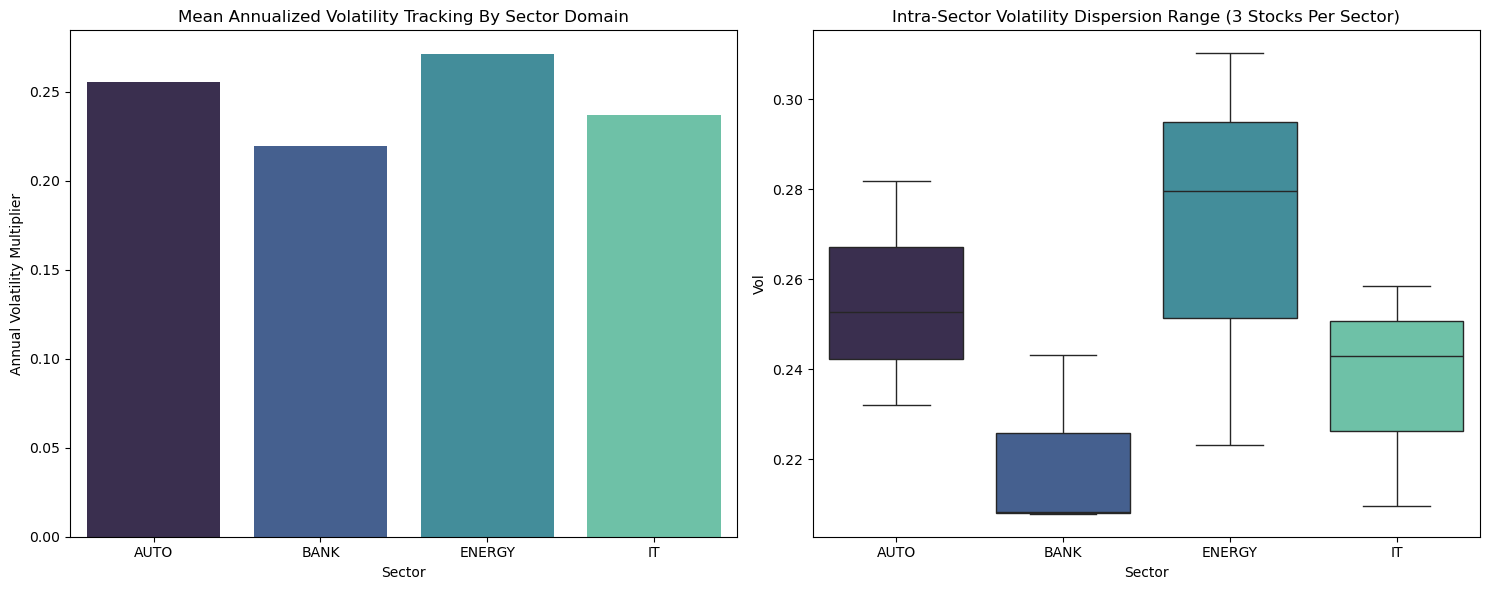

SECTOR STABILITY RANKINGS (Most to Least Stable)
Rank 1: Sector: BANK       | Mean Annualized Volatility: 21.9769%
Rank 2: Sector: IT         | Mean Annualized Volatility: 23.7032%
Rank 3: Sector: AUTO       | Mean Annualized Volatility: 25.5481%
Rank 4: Sector: ENERGY     | Mean Annualized Volatility: 27.0983%
OPTIMAL RISK-RETURN TRADEOFF VERDICT
The sector with the best risk-return tradeoff is: AUTO
Sector Average Return-per-Unit-Risk Ratio: 0.8247

Full Sector Breakdown Matrix:
        Annualized Volatility  Annualized Return  Risk-Return Ratio
Sector                                                             
AUTO                   0.2555             0.2147             0.8247
BANK                   0.2198             0.1108             0.5022
ENERGY                 0.2710             0.1933             0.6851
IT                     0.2370             0.0171             0.0656


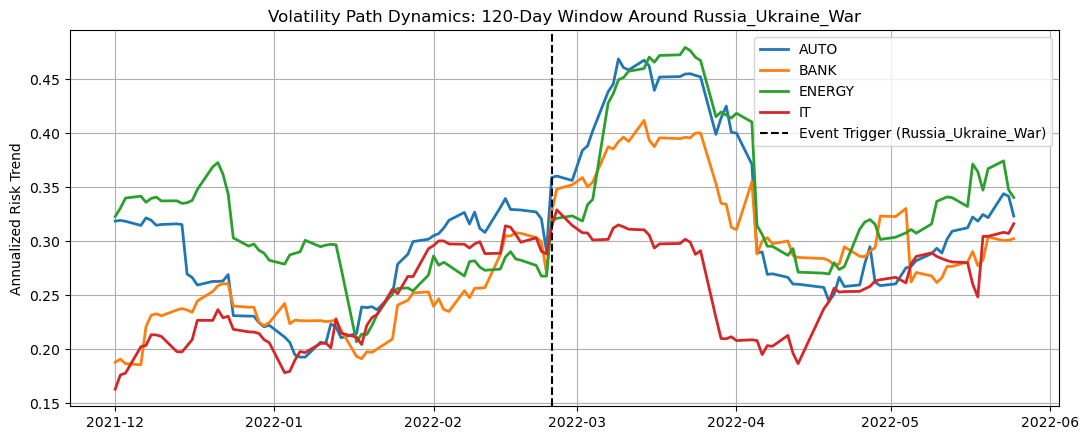

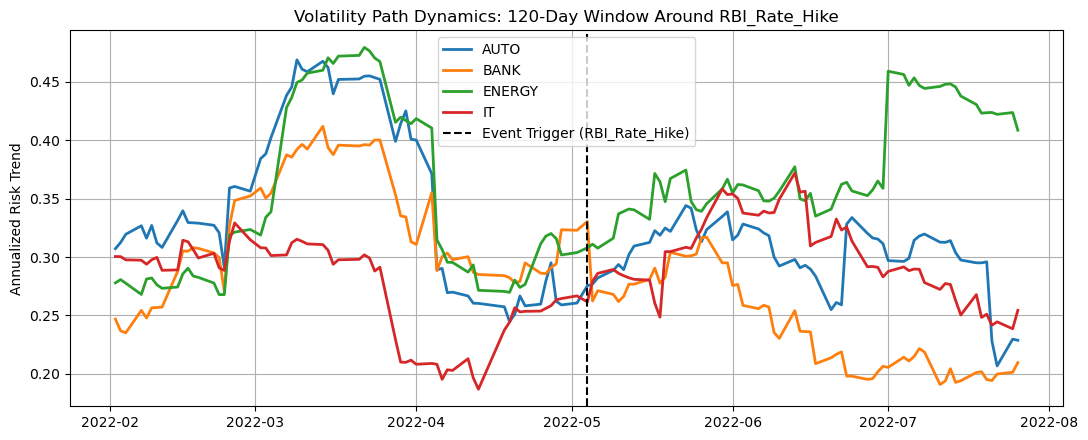

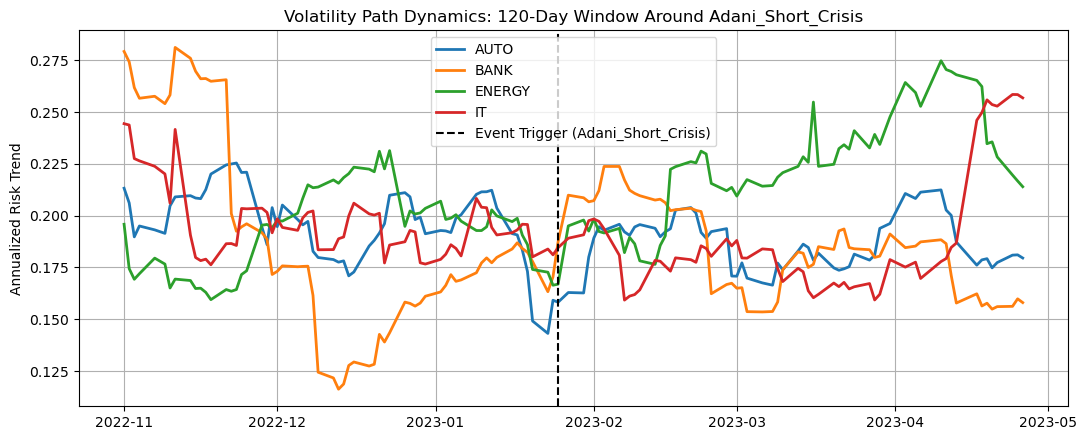


UPDATED VOLATILITY MULTIPLIER RATIO MATRIX
        Russia_Ukraine_War  RBI_Rate_Hike  Adani_Short_Crisis
AUTO              1.365607       0.840455            0.989628
BANK              1.379375       0.726551            1.087654
ENERGY            1.395259       1.048546            1.187761
IT                1.152255       1.099655            1.071099


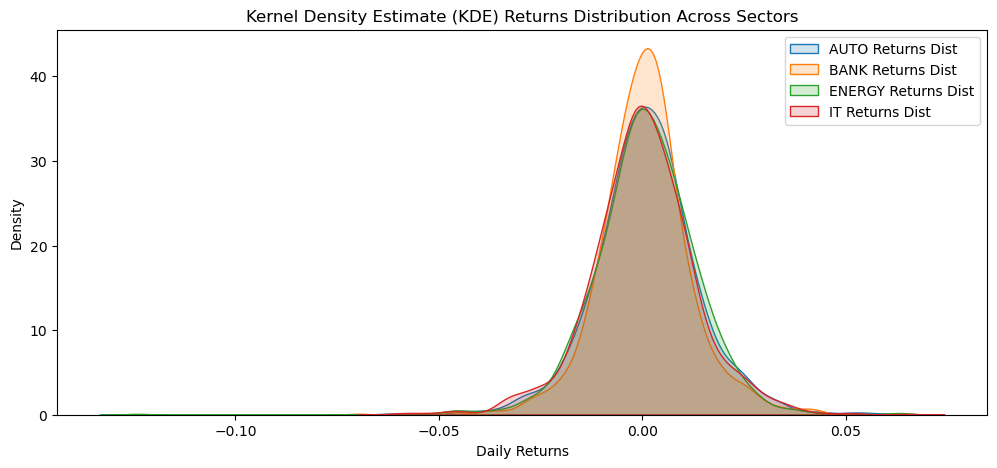

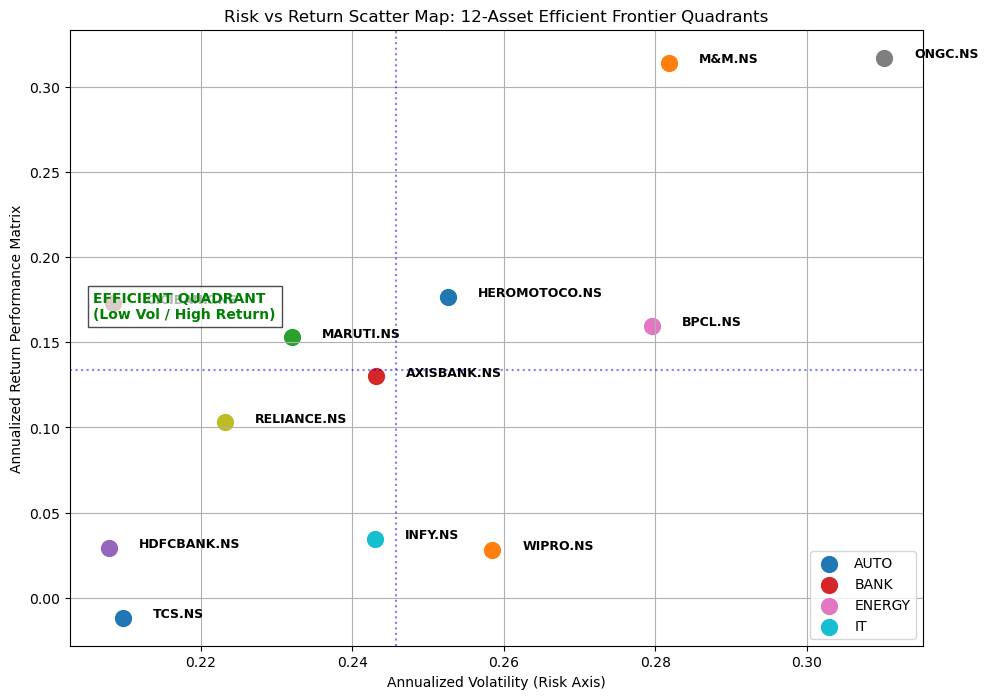

In [12]:
# 1. Compute Full Period Annual Volatilities
annual_vol = returns_df.std() * np.sqrt(252)
sector_series = pd.Series([idx.split('_')[0] for idx in annual_vol.index], index=annual_vol.index)
vol_summary_df = pd.DataFrame({'Vol': annual_vol, 'Sector': sector_series})

# Plot Bar & Box Risk Layouts
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(data=vol_summary_df.groupby('Sector').mean().reset_index(), x='Sector', y='Vol', ax=ax1, palette='mako')
ax1.set_title("Mean Annualized Volatility Tracking By Sector Domain")
ax1.set_ylabel("Annual Volatility Multiplier")

sns.boxplot(data=vol_summary_df, x='Sector', y='Vol', ax=ax2, palette='mako')
ax2.set_title("Intra-Sector Volatility Dispersion Range (3 Stocks Per Sector)")
plt.tight_layout()
plt.savefig("sector_volatility_profiles.png")
plt.show()

# 1. Calculate the metrics per individual asset column
annual_returns = returns_df.mean() * 252
annual_volatility = returns_df.std() * np.sqrt(252)

# Create an asset tracking summary dataframe
asset_perf_df = pd.DataFrame({
    'Annualized Return': annual_returns,
    'Annualized Volatility': annual_volatility,
    'Risk-Return Ratio': annual_returns / annual_volatility  # Performance efficiency metric
})

# Extract the sector name from the column index strings
asset_perf_df['Sector'] = [idx.split('_')[0] for idx in asset_perf_df.index]
asset_perf_df['Ticker'] = [idx.split('_')[1] for idx in asset_perf_df.index]

# 2. Group by Sector to find domain-level performance metrics
sector_performance = asset_perf_df.groupby('Sector').agg({
    'Annualized Volatility': 'mean',
    'Annualized Return': 'mean',
    'Risk-Return Ratio': 'mean'
})

# 3. Rank sectors from Most Stable (Lowest Volatility) to Most Volatile (Highest Volatility)
stability_ranking = sector_performance.sort_values(by='Annualized Volatility', ascending=True)

print("SECTOR STABILITY RANKINGS (Most to Least Stable)")
for rank, (sector, row) in enumerate(stability_ranking.iterrows(), 1):
    print(f"Rank {rank}: Sector: {sector:<10} | Mean Annualized Volatility: {row['Annualized Volatility']:.4%}")

# 4. Identify the Sector with the Best Risk-Return Tradeoff
best_tradeoff_sector = sector_performance['Risk-Return Ratio'].idxmax()
best_tradeoff_value = sector_performance['Risk-Return Ratio'].max()

print("OPTIMAL RISK-RETURN TRADEOFF VERDICT")
print(f"The sector with the best risk-return tradeoff is: {best_tradeoff_sector}")
print(f"Sector Average Return-per-Unit-Risk Ratio: {best_tradeoff_value:.4f}")
print("\nFull Sector Breakdown Matrix:")
print(sector_performance[['Annualized Volatility', 'Annualized Return', 'Risk-Return Ratio']].round(4))

# 2. Stress Testing Matrix Profile
stress_events = {
    'Russia_Ukraine_War': '2022-02-24',
    'RBI_Rate_Hike': '2022-05-04',
    'Adani_Short_Crisis': '2023-01-25'
}

vol_ratio_summary = {}

for event_name, event_date_str in stress_events.items():
    event_date = pd.to_datetime(event_date_str)
    
    try:
        loc_idx = returns_df.index.get_indexer([event_date], method='nearest')[0]
        pre_window = returns_df.iloc[max(0, loc_idx-60):loc_idx]
        post_window = returns_df.iloc[loc_idx:min(len(returns_df), loc_idx+60)]
        
        pre_vol = pre_window.std() * np.sqrt(252)
        post_vol = post_window.std() * np.sqrt(252)
        
        ratios = post_vol / pre_vol
        sector_ratios = ratios.groupby([col.split('_')[0] for col in ratios.index]).mean()
        vol_ratio_summary[event_name] = sector_ratios
        
        # Plot Stress Event Overlay
        plt.figure(figsize=(11, 4.5))
        for sector in sector_corr.index:
            sec_cols = [c for c in returns_df.columns if c.startswith(sector)]
            rolling_sec_vol = returns_df[sec_cols].rolling(20).std().mean(axis=1) * np.sqrt(252)
            
            plot_slice = rolling_sec_vol.iloc[max(0, loc_idx-60):min(len(returns_df), loc_idx+60)]
            plt.plot(plot_slice.index, plot_slice, label=sector, linewidth=2)
            
        plt.axvline(event_date, color='black', linestyle='--', label=f'Event Trigger ({event_name})')
        plt.title(f"Volatility Path Dynamics: 120-Day Window Around {event_name}")
        plt.ylabel("Annualized Risk Trend")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.savefig(f"stress_event_{event_name}.png")
        plt.show()
    except Exception as e:
        print(f"Could not compute visualization window for {event_name}: {e}")

print("\nUPDATED VOLATILITY MULTIPLIER RATIO MATRIX")
ratio_df = pd.DataFrame(vol_ratio_summary)
print(ratio_df)

# 3. Distributions (KDE) and Risk-Return Scatter Map
plt.figure(figsize=(12, 5))
for sector in sector_corr.index:
    sec_cols = [c for c in returns_df.columns if c.startswith(sector)]
    sns.kdeplot(returns_df[sec_cols].mean(axis=1), label=f'{sector} Returns Dist', fill=True, alpha=0.2)
plt.title("Kernel Density Estimate (KDE) Returns Distribution Across Sectors")
plt.xlabel("Daily Returns")
plt.legend()
plt.savefig("sector_kde_distribution.png")
plt.show()

# 4. Risk-Return Scatter Map (The Efficient Quadrant Map)
annual_returns = returns_df.mean() * 252

plt.figure(figsize=(11, 8))
mean_ret_market = annual_returns.mean()
mean_vol_market = annual_vol.mean()

# Scatter plot point mappings
for ticker_col in returns_df.columns:
    sec = ticker_col.split('_')[0]
    plt.scatter(annual_vol[ticker_col], annual_returns[ticker_col], s=130, 
                label=sec if sec not in plt.gca().get_legend_handles_labels()[1] else "")
    plt.text(annual_vol[ticker_col]+0.004, annual_returns[ticker_col], ticker_col.split('_')[1], fontsize=9, weight='bold')

plt.axhline(mean_ret_market, color='blue', linestyle=':', alpha=0.5)
plt.axvline(mean_vol_market, color='blue', linestyle=':', alpha=0.5)

plt.text(mean_vol_market - 0.04, mean_ret_market + 0.03, "EFFICIENT QUADRANT\n(Low Vol / High Return)", 
         color='green', fontsize=10, weight='bold', bbox=dict(facecolor='white', alpha=0.7))

plt.title("Risk vs Return Scatter Map: 12-Asset Efficient Frontier Quadrants")
plt.xlabel("Annualized Volatility (Risk Axis)")
plt.ylabel("Annualized Return Performance Matrix")
plt.legend(loc='lower right')
plt.grid(True)
plt.savefig("risk_return_quadrant_map.png")
plt.show()